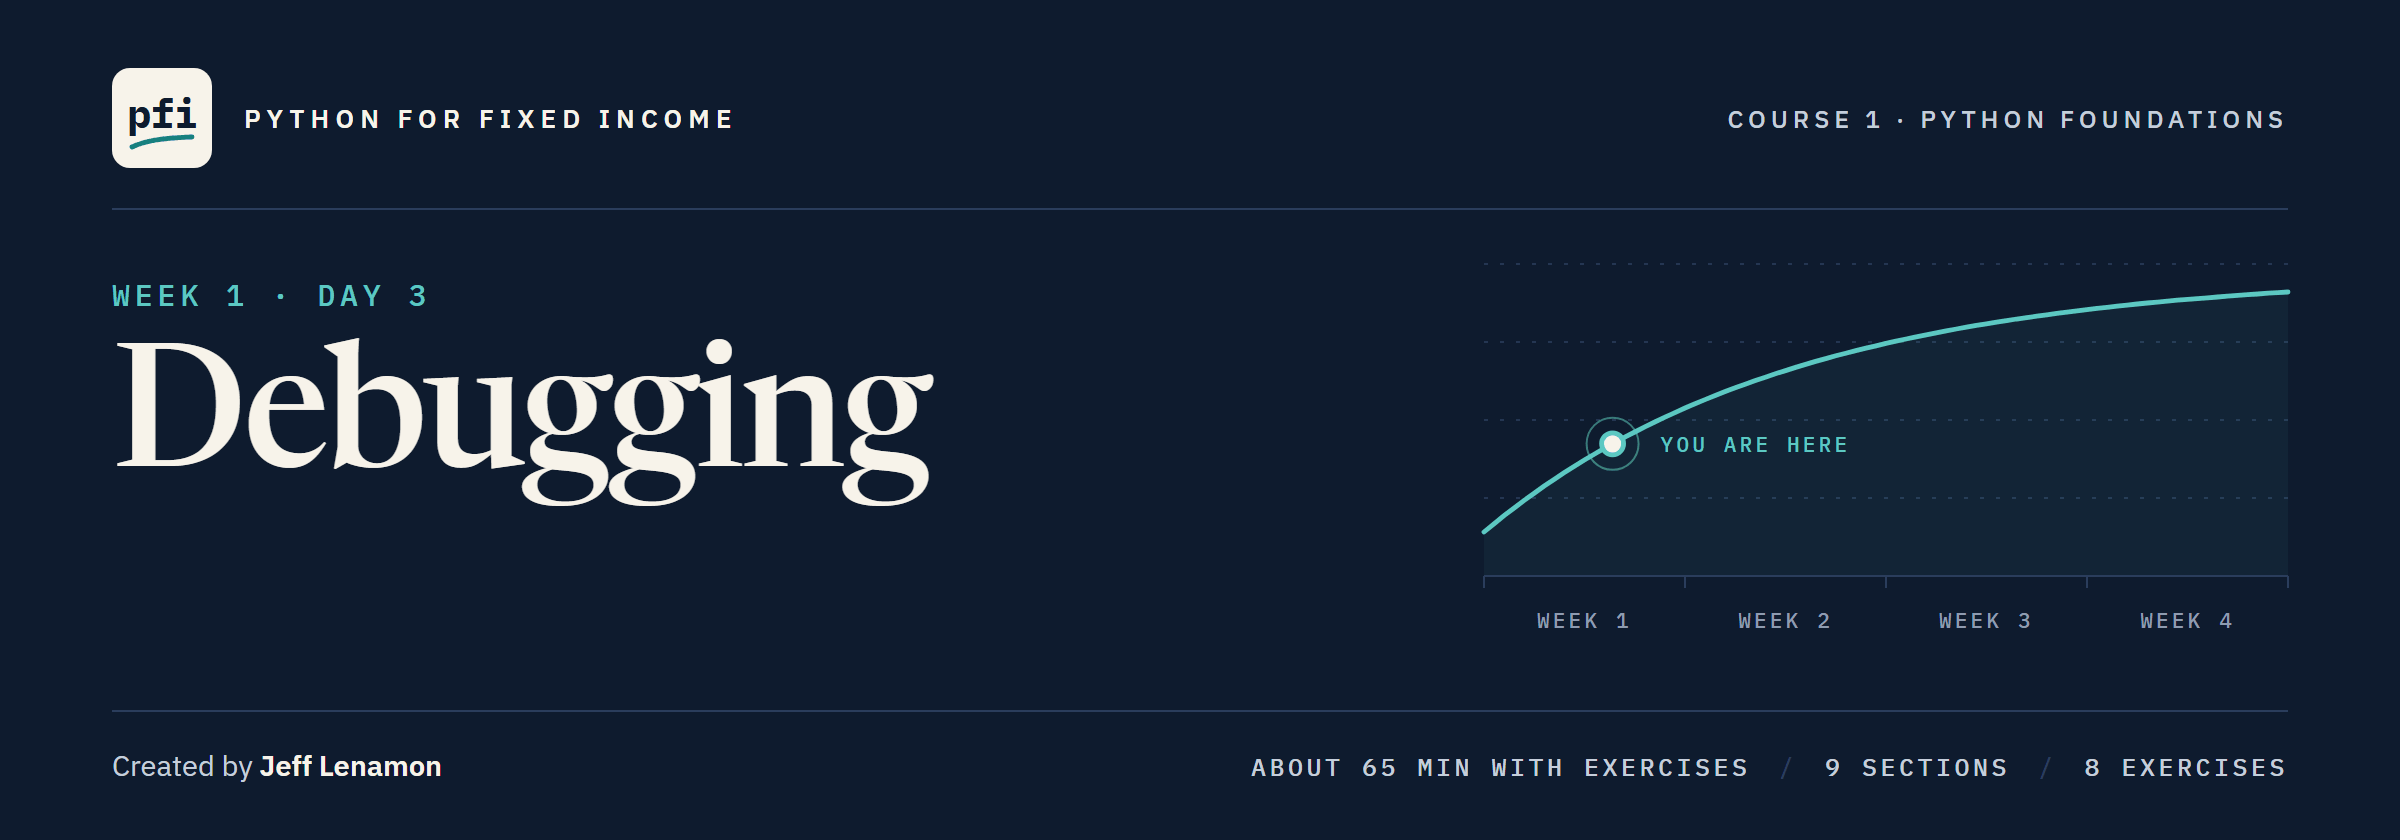

# Debugging

Week 1, Day 3. Finding and fixing the mistakes in code, using broken calculations from a bond desk.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day3/03_debugging.ipynb)

## The Desk Lead's Fifth Note

> A new analyst wrote this week's code for our book. Half of it stops in red. Worse, some of it runs and prints numbers I do not trust: QVNE's income came out at 7,875,000. Fix every cell, find the wrong numbers, and make the book check its own totals.

A mistake in code is a **bug**; finding and fixing it is **debugging**.
Everyone writes bugs, beginners and experts alike.
When Python cannot carry out a line, it stops and says what went wrong and where: it **raises** an error.
The red blocks below are there on purpose.

### The Book in One Cell

**Run the next cell to store the book again.**

In [1]:
# the book's four lists, one per column, the bonds in the same order
ticker_list = ['QVNE', 'DNMR', 'PLWK', 'HLVF']
coupon_list = [5.25, 6.125, 4.75, 7.5]
price_list = [98.5, 103.25, 95.0, 101.0]
face_list = [1500000, 500000, 750000, 250000]
print(f'The desk holds {len(ticker_list)} bonds and {sum(face_list):,} face')

The desk holds 4 bonds and 3,000,000 face


## Your Route Through Day 3

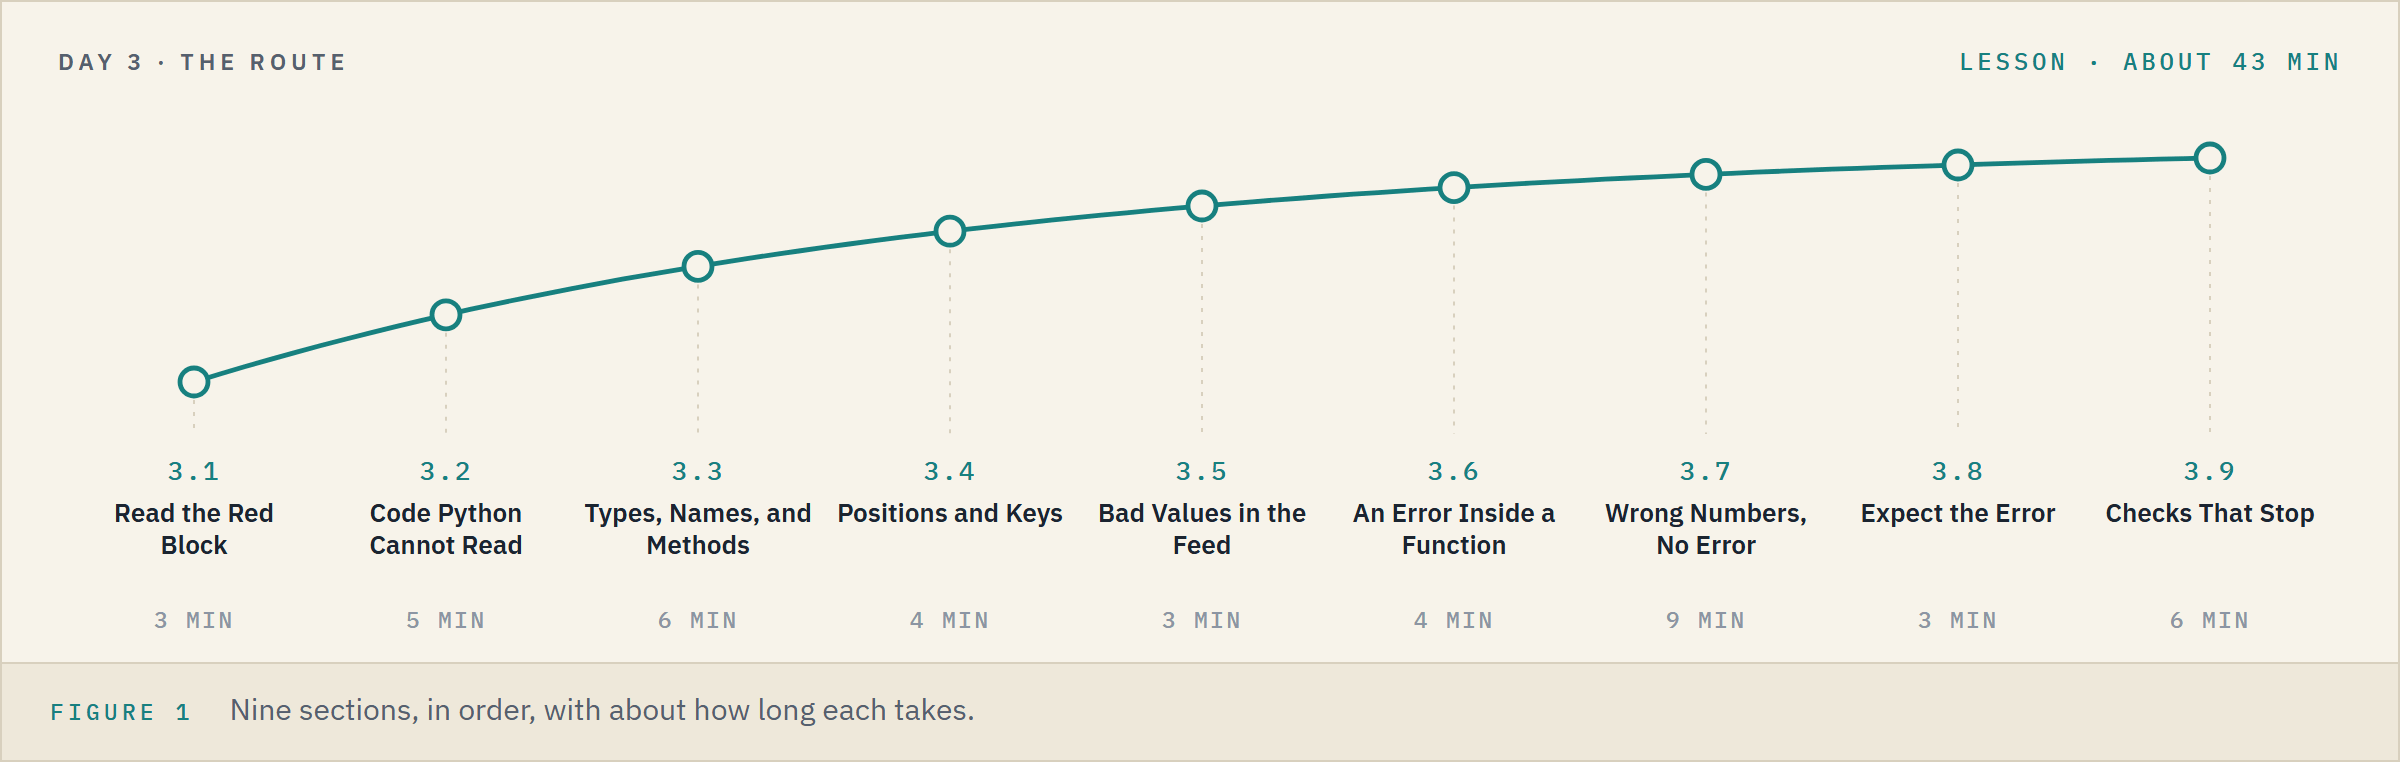

**Time.** About 43 minutes for the lesson, then about 24 for the eight exercises.

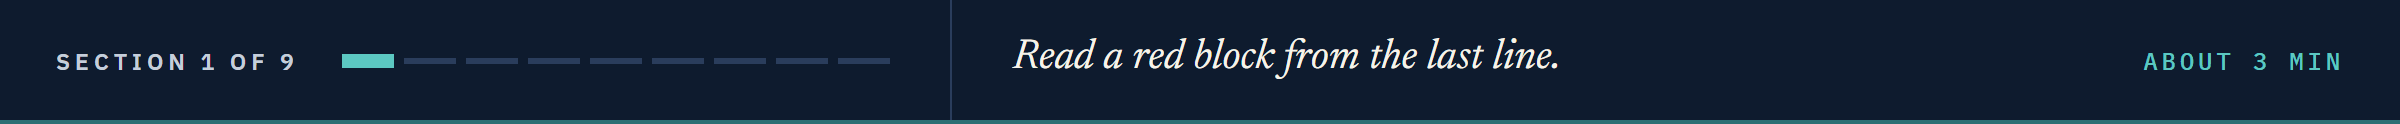

## 3.1 Read the Red Block

### Run, Read, Fix: A Misspelled Name

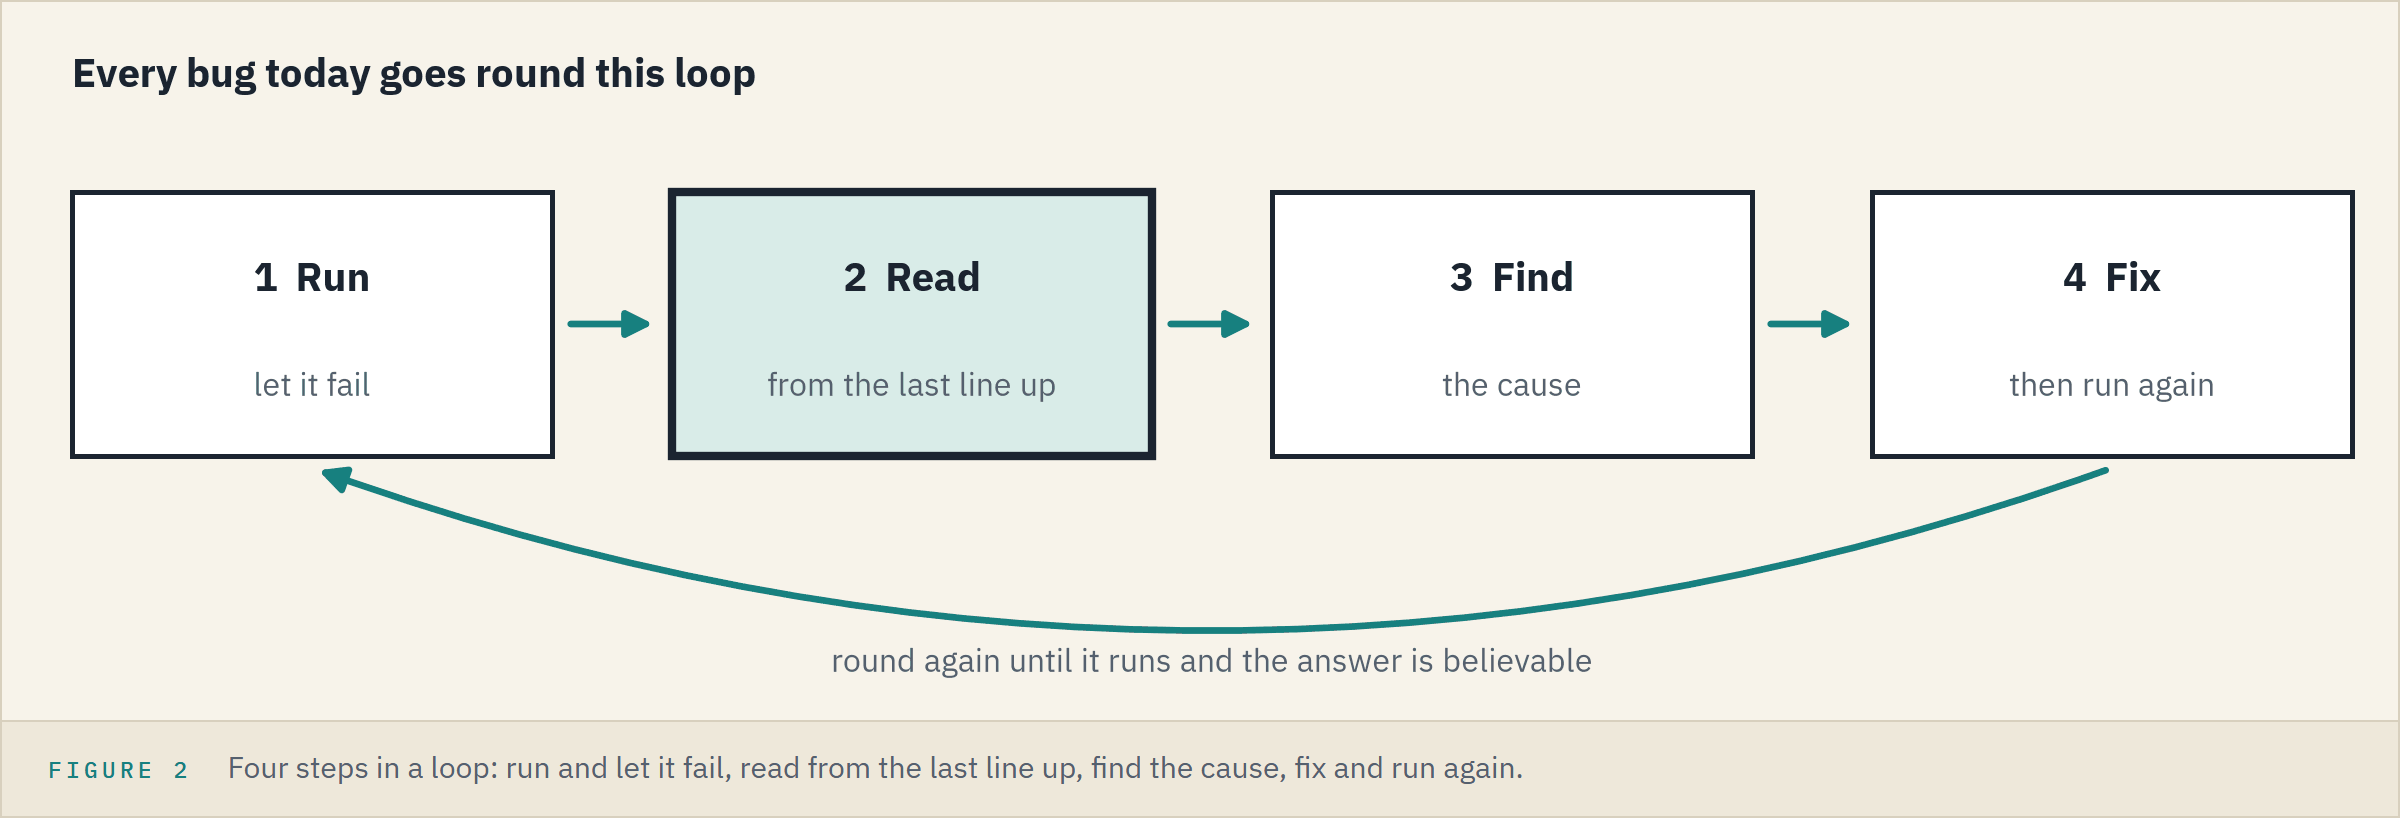

Q. The analyst prints QVNE's coupon. What does Python say?

Q. Spell the name as it was stored.

In [2]:
# the analyst's first cell: this cell is meant to fail
coupon = 5.25
print('The coupon is', cupon)

NameError: name 'cupon' is not defined

In [3]:
# the name spelled as it was stored
coupon = 5.25
print('The coupon is', coupon)

The coupon is 5.25


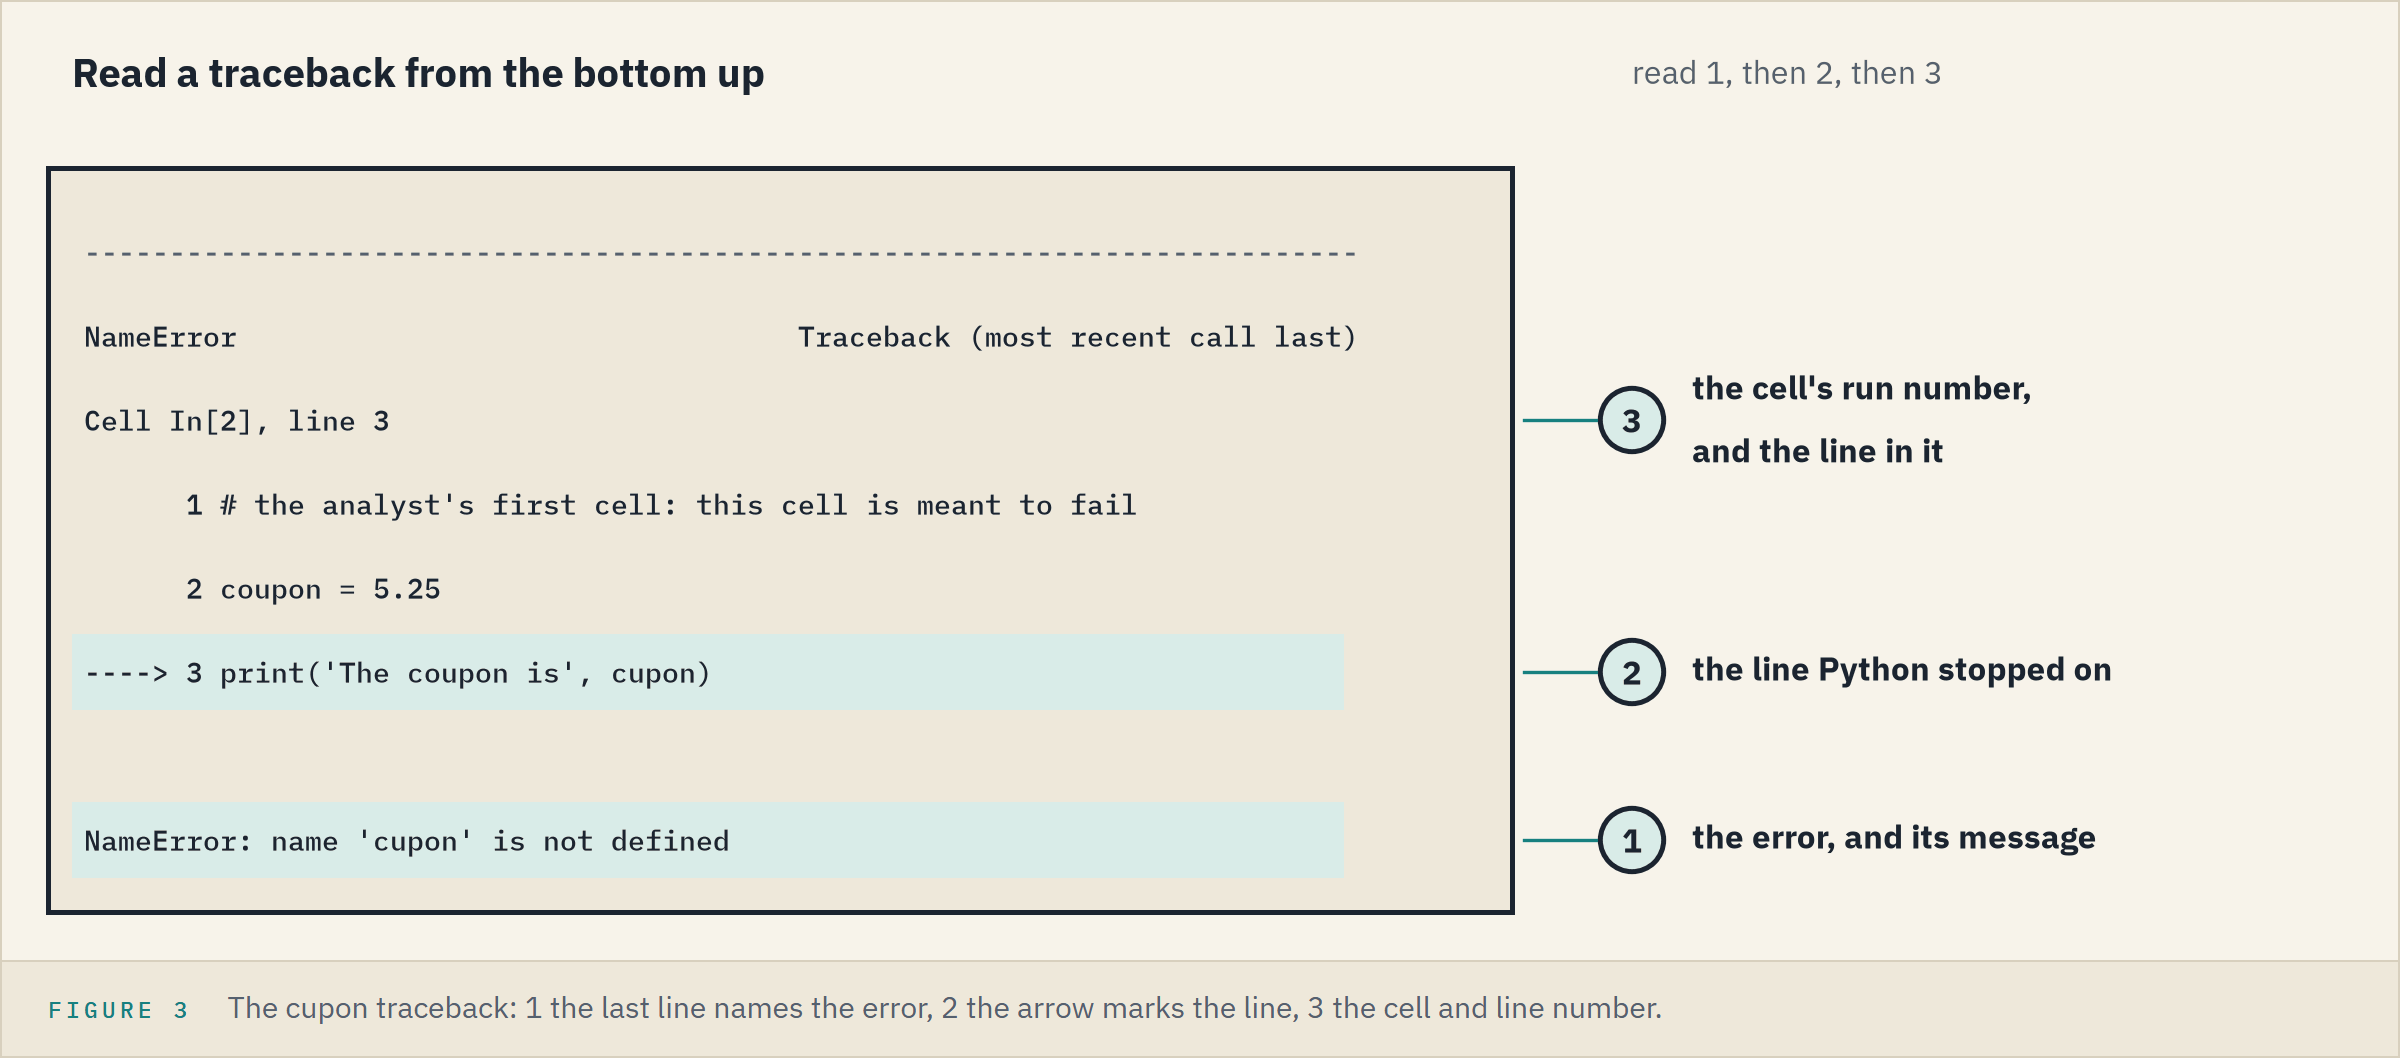

`coupon` was stored and `cupon` printed: to Python, two different names.
`In[2]` is the run number shown beside the cell, so yours may differ.
Colab may name the cell another way; the arrow and the last line read the same.

**Every traceback answers three questions: what type, what message, which line.**

> STORY: On September 9, 1947, engineers working on Harvard's Mark II computer found a moth inside the machine.
> Someone taped it into the log book, noting the first actual case of a bug being found.
> Engineers already called faults "bugs": Thomas Edison used the word that way in a letter in 1878.
> The story is often told about Grace Hopper, who worked on the Mark II, but the museum notes the log book was probably not hers.
>
> Sources: [JSTOR Daily](https://daily.jstor.org/the-bug-in-the-computer-bug-story/); [the museum's object record](https://americanhistory.si.edu/collections/object/nmah_334663)

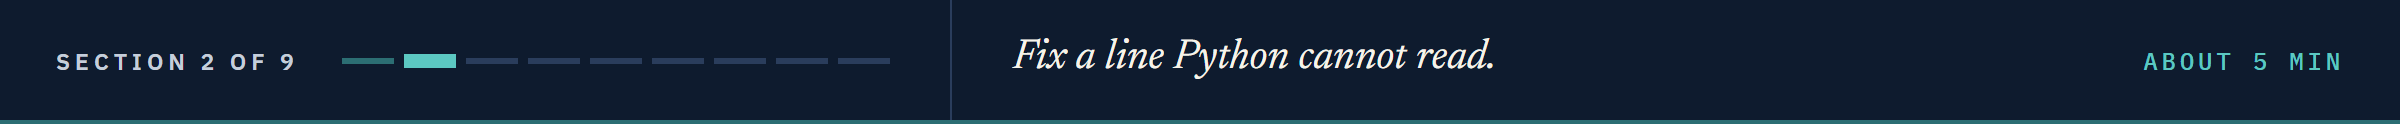

## 3.2 Code Python Cannot Read

### A Missing Colon, Then a Missing Indent

A `SyntaxError` means Python could not read the cell's grammar, its **syntax** (Part 1).

Q. Print every ticker.

Q. Add the colon, and leave out the indent.

Q. Both in place.

In [4]:
# this cell is meant to fail
print('The tickers:')
for ticker in ticker_list
    print(ticker)

SyntaxError: expected ':' (468422522.py, line 3)

In [5]:
# the colon added, the indent left out: this cell is meant to fail
print('The tickers:')
for ticker in ticker_list:
print(ticker)

IndentationError: expected an indented block after 'for' statement on line 3 (1579859704.py, line 4)

In [6]:
# a for line ends with a colon, and the line inside it is indented
print('The tickers:')
for ticker in ticker_list:
    print(ticker)

The tickers:
QVNE
DNMR
PLWK
HLVF


Neither failing cell printed `The tickers:`: one slip in its grammar, and nothing in the cell runs.
A syntax error has no arrow: the `^` marks the spot.
`for`, `if`, `elif`, `else`, `while`, `def`, and `with` lines end in a colon (Part 2, Day 2).

### One Equals Sign or Two

Q. Does QVNE trade at par?

Q. Ask with `==`.

In [7]:
# this cell is meant to fail
price = 98.5
if price = 100:
    print('QVNE trades at par')
else:
    print('QVNE does not trade at par')

SyntaxError: invalid syntax. Maybe you meant '==' or ':=' instead of '='? (3779317513.py, line 3)

In [8]:
# == asks whether two values are equal; = stores a value
price = 98.5
if price == 100:
    print('QVNE trades at par')
else:
    print('QVNE does not trade at par')

QVNE does not trade at par


Python suggests the fix: `=` stores, `==` tests (Part 2).
The `:=` it offers is a tool this course does not use.

### A Bracket Left Open

Q. Put a fifth coupon, 6.0, in a new list.

Q. Close the bracket.

In [9]:
# this cell is meant to fail
new_coupon_list = [5.25, 6.125, 4.75, 7.5, 6.0
print(new_coupon_list)

SyntaxError: '[' was never closed (585566977.py, line 2)

In [10]:
# the closing bracket added
new_coupon_list = [5.25, 6.125, 4.75, 7.5, 6.0]
print(new_coupon_list)

[5.25, 6.125, 4.75, 7.5, 6.0]


Every bracket, parenthesis, and quote needs its partner.
Some slips are only noticed on a later line, so if the marked line looks fine, look at the line above.

**Excel side by side.** Excel refuses too: type `=1+` and press Enter, and Excel will not take the formula until it is fixed.

**From here the code is good Python: it runs until it reaches a line it cannot carry out.**

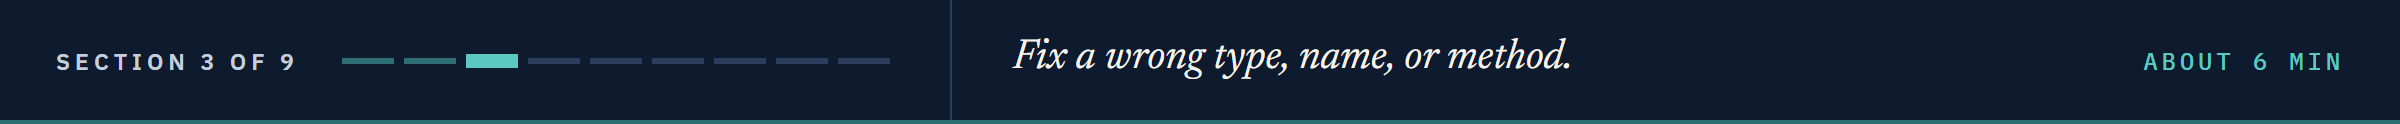

## 3.3 Types, Names, and Methods

### Text Times a Number

Q. QVNE's face arrives from a file as text. Work out its coupon income.

Q. What type is each name, and what is the text times 2?

Q. Convert the face, then work out the income.

In [11]:
# the face as it arrived from a file, in quotes: this cell is meant to fail
face = '1500000'
coupon = 5.25
income = face * coupon / 100

TypeError: can't multiply sequence by non-int of type 'float'

In [12]:
# type(), from Part 1
print(type(face))
print(type(coupon))
# text times a whole number
print(face * 2)

<class 'str'>
<class 'float'>
15000001500000


In [13]:
# int() turns the text into a whole number first
face = int(face)
income = face * coupon / 100
print('The annual coupon income is', income)

The annual coupon income is 78750.0


A type error: the operation is fine, the type is wrong.
**Sequence** means items in a row, such as a string's characters; **non-int**, not a whole number.
`face` is text, as Day 2's file gave text; times a whole number, text repeats, as `=REPT("1500000",2)` does in Excel.

**Excel side by side.** If A1 holds 1500000 stored as text, `=A1*5.25/100` still returns 78750: Excel's arithmetic converts text that looks like a number.
Python never converts for you.

### A Module Not Loaded

Q. Round QVNE's price down to whole points with `floor`, from the `math` module.

Q. Import `math` first.

In [14]:
# floor() rounds down to the whole number below: this cell is meant to fail
whole_points = math.floor(98.5)
print(whole_points)

NameError: name 'math' is not defined

In [15]:
# load the math module first, as in Day 0, then use it
import math
whole_points = math.floor(98.5)
print(whole_points)

98


The spelling is right: a module's name exists only once it is imported.
Built-in tools such as `print`, `len`, and `sum` are ready from the start.

**Excel side by side.** `=INT(98.5)` returns 98, as `math.floor(98.5)` does: both round down.

### A Method That Is Not There

Q. Add a fifth ticker, ZXMT, to the end of the list.

Q. Which names does a list carry, and what does `append` do?

Q. Add ZXMT with `append`, then `pop()` it off, so the book keeps four bonds.

In [16]:
# this cell is meant to fail
ticker_list.add('ZXMT')

AttributeError: 'list' object has no attribute 'add'

In [17]:
# dir() lists the names a list carries; Python's own start with _, so the filter drops them
print([name for name in dir(ticker_list) if not name.startswith('_')])
# help() on a method: its name with no brackets after it
help(ticker_list.append)

['append', 'clear', 'copy', 'count', 'extend', 'index', 'insert', 'pop', 'remove', 'reverse', 'sort']
Help on built-in function append:

append(object, /) method of builtins.list instance
    Append object to the end of the list.



In [18]:
# append() adds at the end; pop() takes the last item off again
ticker_list.append('ZXMT')
print(ticker_list)
ticker_list.pop()
print(ticker_list)

['QVNE', 'DNMR', 'PLWK', 'HLVF', 'ZXMT']
['QVNE', 'DNMR', 'PLWK', 'HLVF']


**Object** is Python's word for any value it holds: a list, a string, a number.
An **attribute** is anything reached from an object with a dot; Part 1's methods are attributes.
A list has `append`, and no `add`; `startswith()` is Day 2's `endswith()` for the other end.
`help()` (Part 2) ends on the docstring; pass over the `/`.

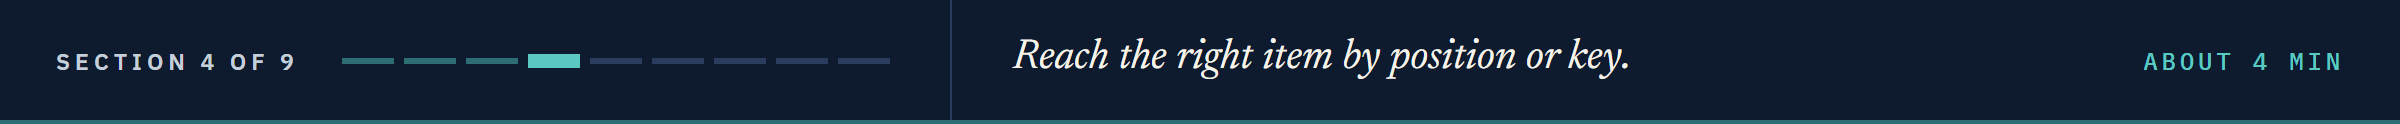

## 3.4 Positions and Keys

### Counting From One

Q. Print each bond's ticker, by position.

Q. Fix the range, then loop with no position.

In [19]:
# this cell is meant to fail
for i in range(1, 5):
    print(ticker_list[i])

DNMR
PLWK
HLVF


IndexError: list index out of range

In [20]:
# range(4) gives 0, 1, 2, 3
for i in range(4):
    print(ticker_list[i])
# better still: loop over the list itself, with no position to get wrong
for ticker in ticker_list:
    print(ticker)

QVNE
DNMR
PLWK
HLVF
QVNE
DNMR
PLWK
HLVF


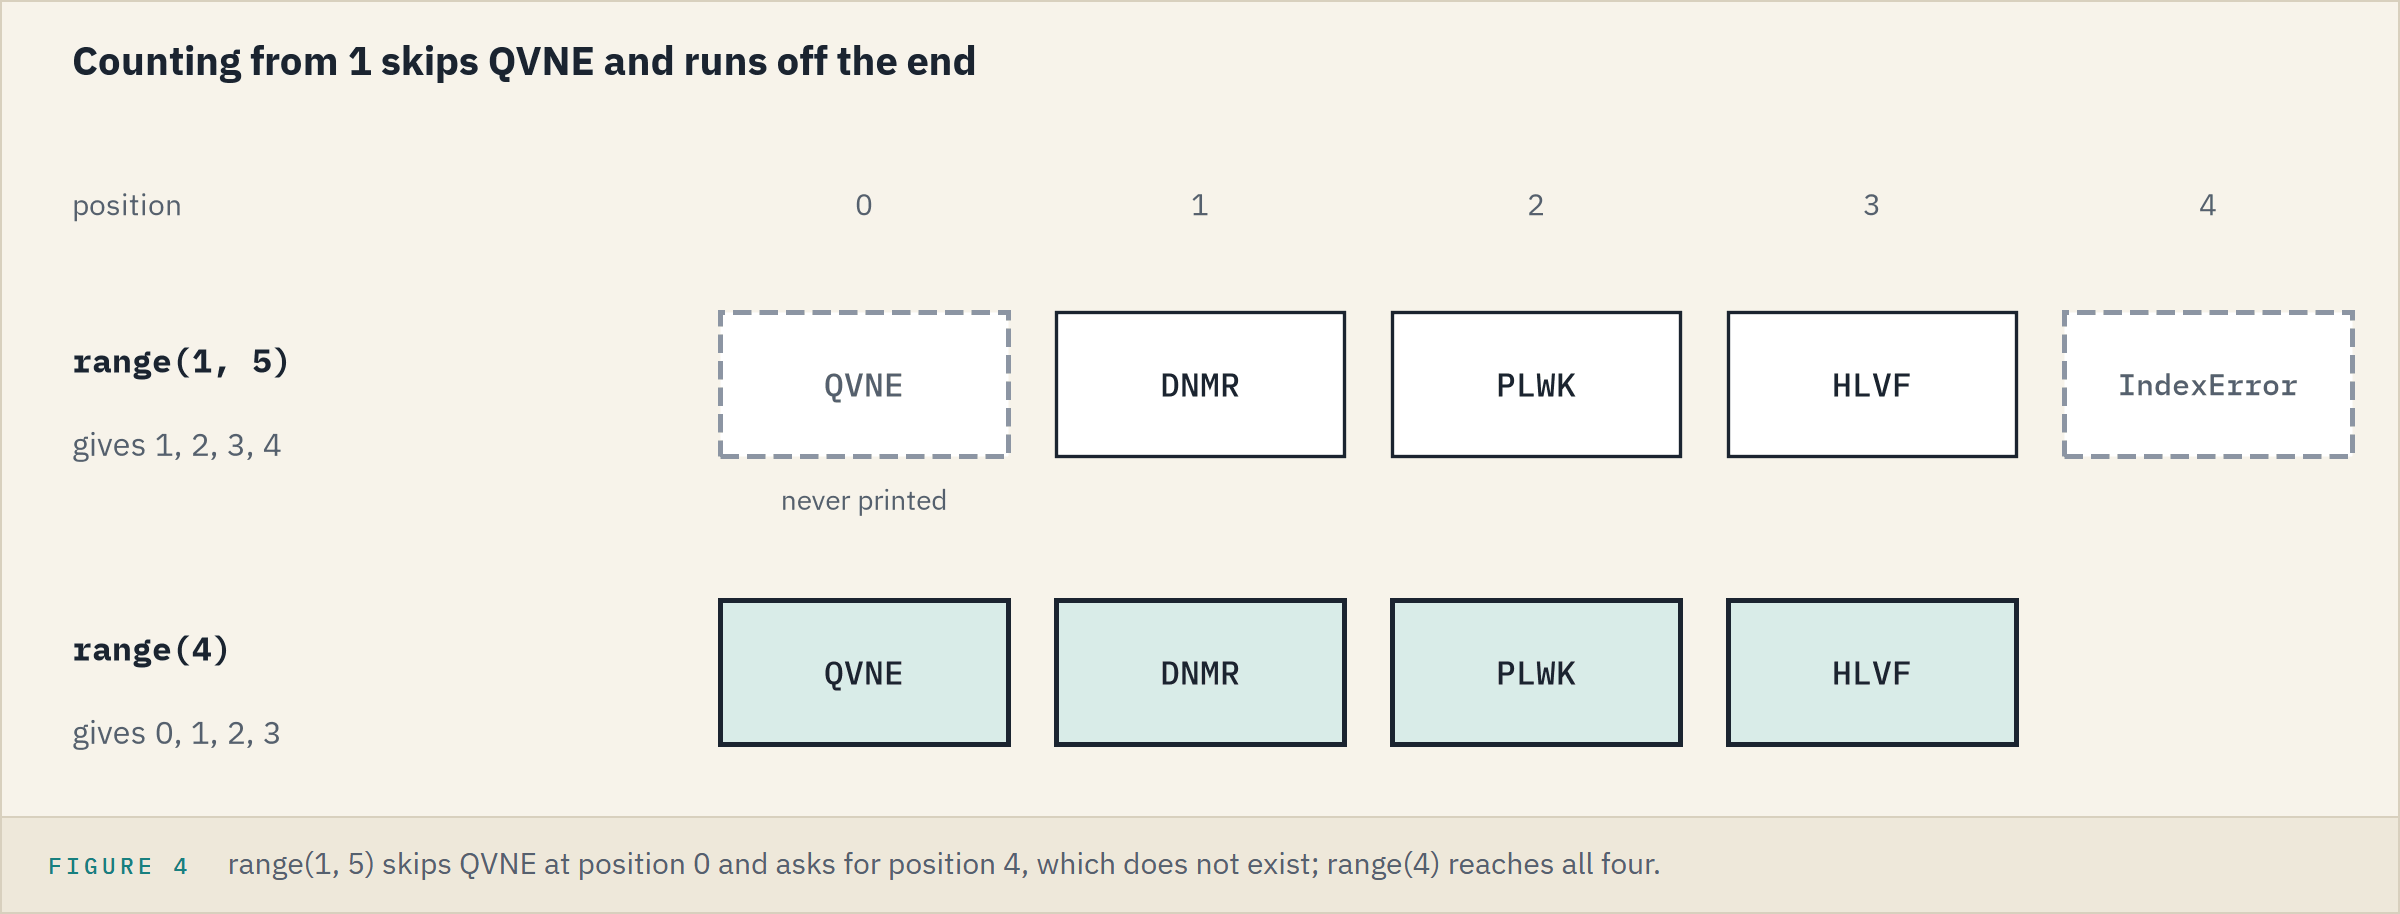

Counting from 1 is an **off-by-one** bug, one of the commonest there is.

**Excel side by side.** Excel counts from 1: `=INDEX(A1:A4,1)` returns the first item.
`=INDEX(A1:A4,5)` on four cells returns `#REF!`, Excel's `IndexError`.

### A Key: Quotes, Then Capitals

Q. Store QVNE as a dictionary.

Q. Quote the key, and print the coupon.

Q. List its keys, then use the key as stored.

In [21]:
# this cell is meant to fail
bond = {Ticker: 'QVNE', 'Coupon': 5.25, 'Price': 98.5}
print(bond)

NameError: name 'Ticker' is not defined

In [22]:
# the key quoted: this cell is meant to fail
bond = {'Ticker': 'QVNE', 'Coupon': 5.25, 'Price': 98.5}
print(bond['coupon'])

KeyError: 'coupon'

In [23]:
# .keys() shows how each key is spelled
print(bond.keys())
print(bond['Coupon'])

dict_keys(['Ticker', 'Coupon', 'Price'])
5.25


Unquoted, `Ticker` reads as a variable's name, and no such variable exists.
The key is 'Coupon': keys match exactly, capitals included (Part 1).

**Excel side by side.** Excel's lookups ignore case: with labels in A1:A3 and values in B1:B3, `=XLOOKUP("coupon",A1:A3,B1:B3)` finds Coupon.
Excel would never show you this bug.

**Now the code is right and the data is not.**

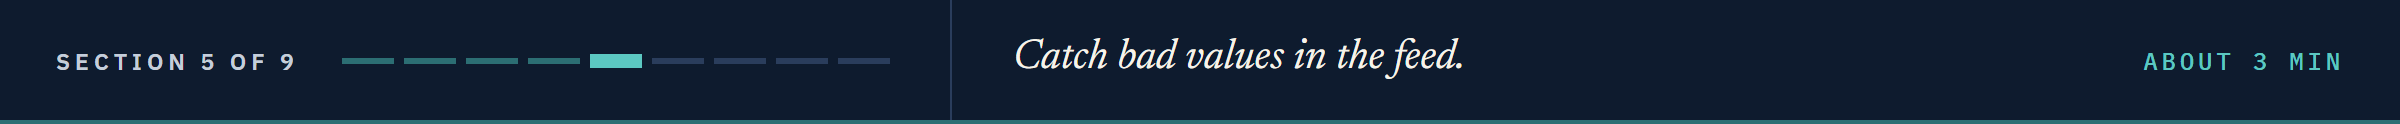

## 3.5 Bad Values in the Feed

### A Percent Sign, Then a Zero

Q. A broker sends QVNE's coupon as '5.25%'. Make it a number.

Q. Take the percent sign out first.

Q. Today's feed has a 0 for PLWK. Print each bond's current yield.

Q. Report the bad price and skip it.

In [24]:
# the broker's coupon, with a percent sign: this cell is meant to fail
coupon_text = '5.25%'
coupon = float(coupon_text)

ValueError: could not convert string to float: '5.25%'

In [25]:
# replace the percent sign with nothing, as in Part 1, then convert
coupon = float(coupon_text.replace('%', ''))
print(coupon)

5.25


In [26]:
# today's feed, with a 0 for PLWK: this cell is meant to fail
feed_price_list = [98.5, 103.25, 0, 101.0]
for ticker, coupon, price in zip(ticker_list, coupon_list, feed_price_list):
    print(ticker, round(coupon / price * 100, 2))

QVNE 5.33
DNMR 5.93


ZeroDivisionError: float division by zero

In [27]:
# report a price that cannot be right, and skip it
for ticker, coupon, price in zip(ticker_list, coupon_list, feed_price_list):
    if price <= 0:
        print(ticker, 'has a bad price:', price)
    else:
        print(ticker, round(coupon / price * 100, 2))

QVNE 5.33
DNMR 5.93
PLWK has a bad price: 0
HLVF 7.43


A value error: right type, wrong content; `float()` takes text, but not a percent sign.

**Excel side by side.** `=VALUE("5.25%")` returns 0.0525: Excel reads the percent sign and divides by 100.
Our fix gives 5.25, in percent, the way the book stores coupons.

The zero stopped the loop after two bonds: report a bad price, never hide it.

**Fix the data, not the formula.**

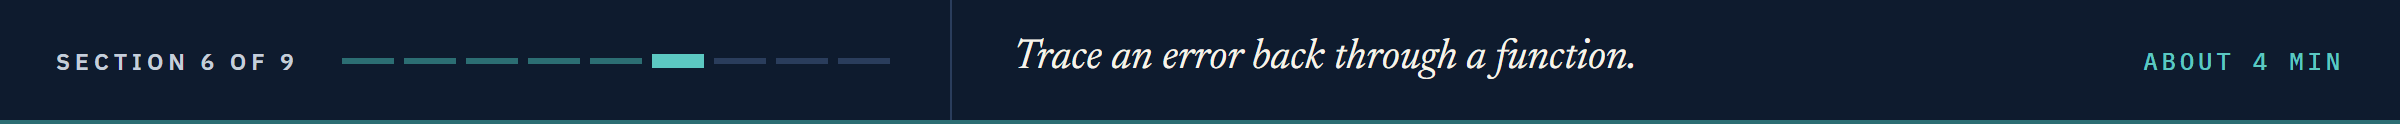

## 3.6 An Error Inside a Function

### Two Arrows

Q. Store Part 2's `current_yield`.

Q. Run it on a feed where PLWK's price came through as text.

Q. Make each price a number before it goes in.

In [28]:
# Part 2's current_yield, word for word
def current_yield(coupon, price):
    """Take coupon (percent) and price (per 100 face); return current yield in percent."""
    return coupon / price * 100

In [29]:
# today's feed, with PLWK's price as text: this cell is meant to fail
feed_price_list = [98.5, 103.25, '95.0', 101.0]
for ticker, coupon, price in zip(ticker_list, coupon_list, feed_price_list):
    print(ticker, round(current_yield(coupon, price), 2))

QVNE 5.33
DNMR 5.93


TypeError: unsupported operand type(s) for /: 'float' and 'str'

In [30]:
# make every price a number before the function sees it
for ticker, coupon, price in zip(ticker_list, coupon_list, feed_price_list):
    price = float(price)
    print(ticker, round(current_yield(coupon, price), 2))

QVNE 5.33
DNMR 5.93
PLWK 5.0
HLVF 7.43


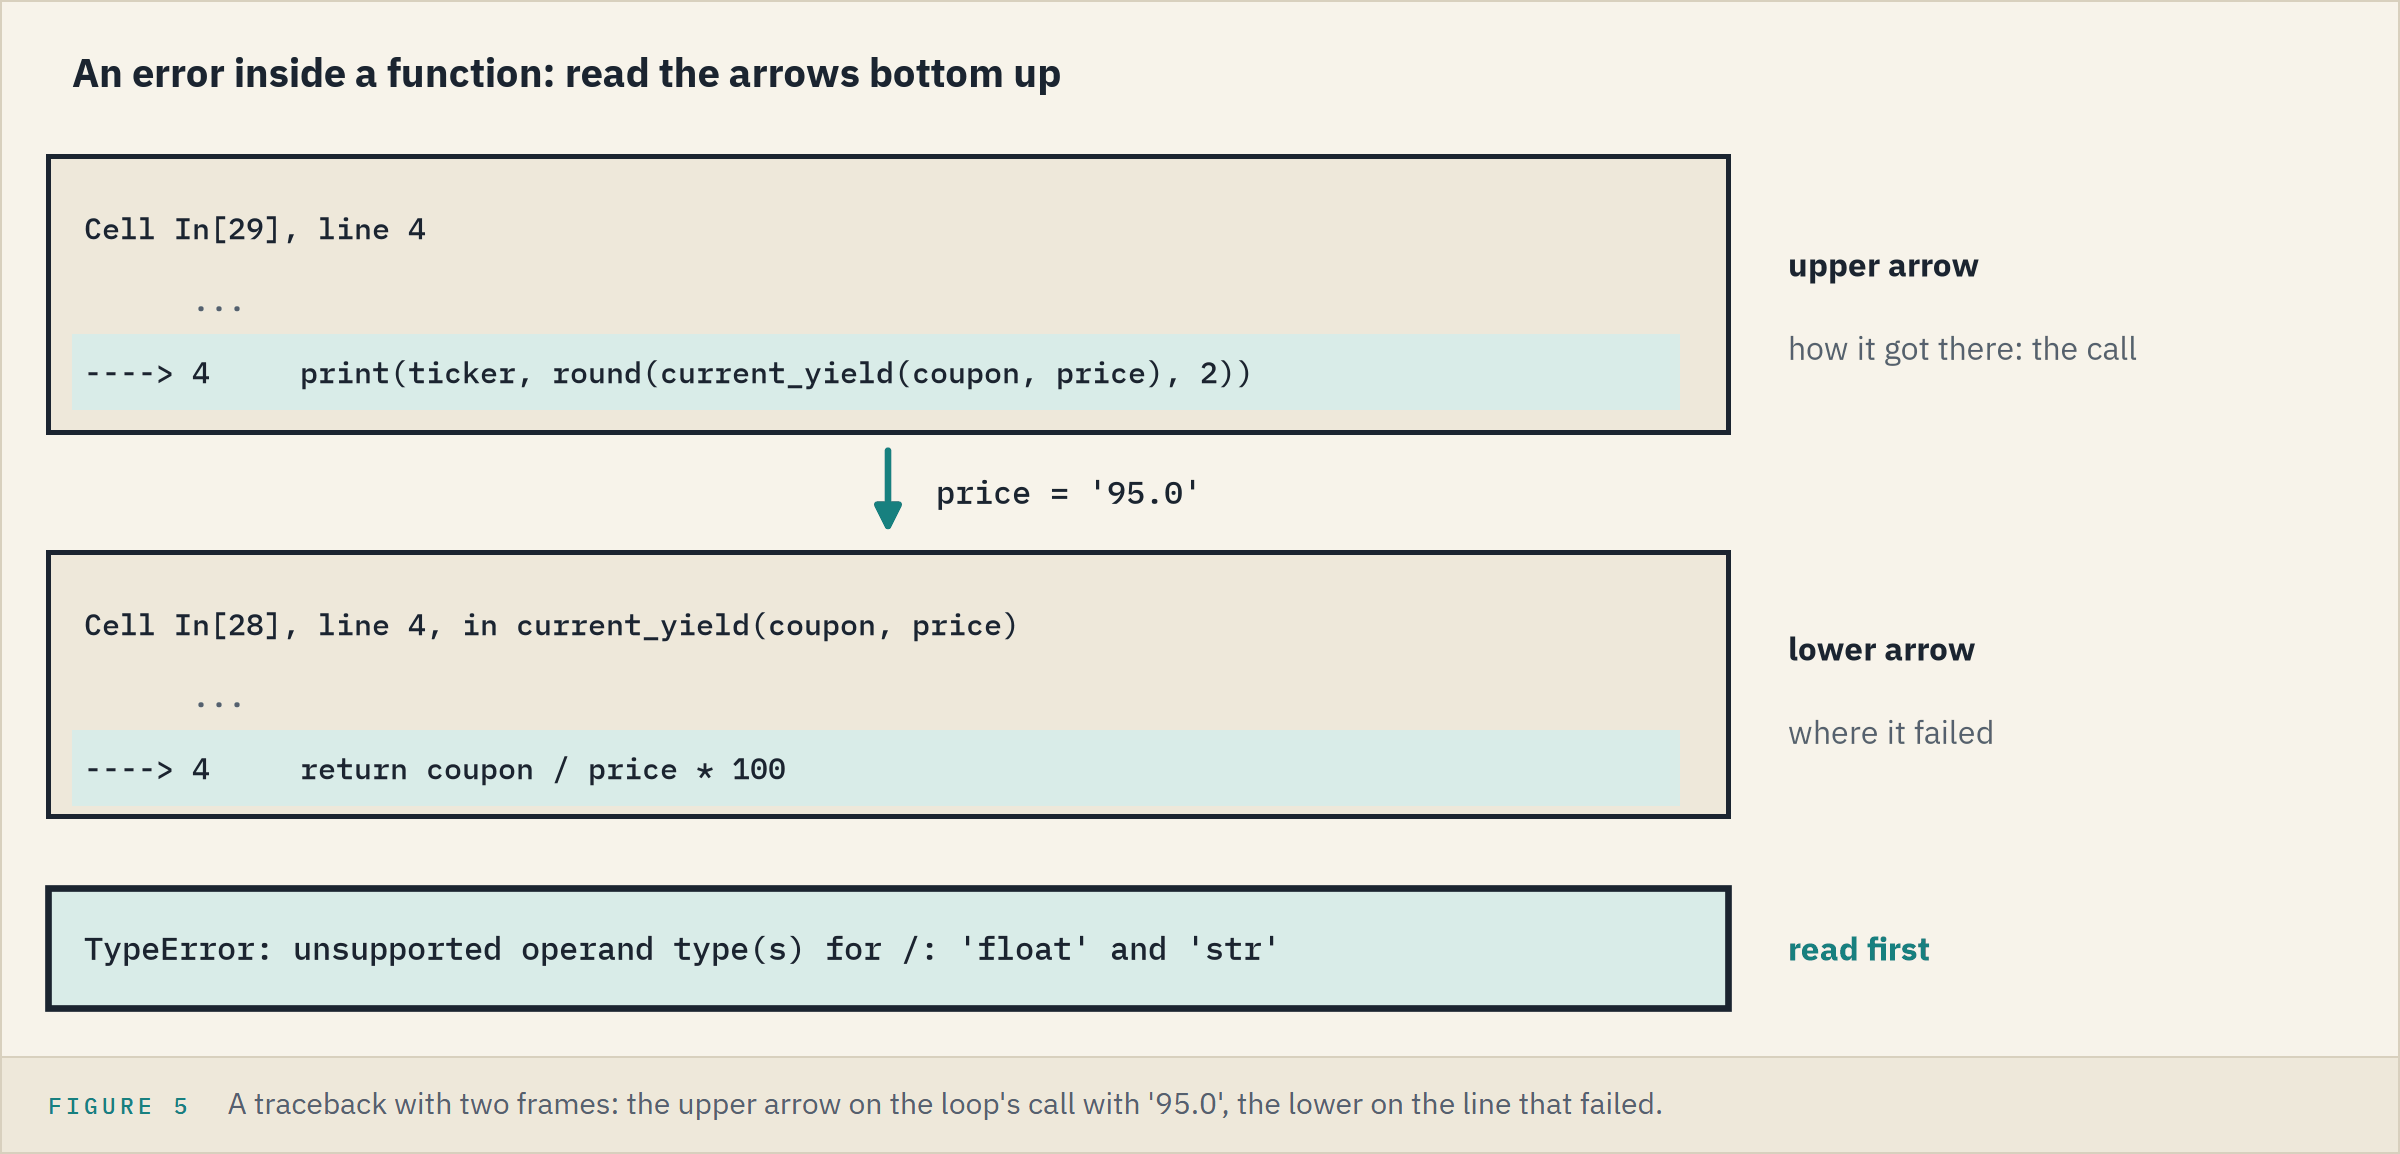

Bottom first: a `TypeError`, a number divided by text.
`most recent call last`, at the top of every traceback, means the newest step is printed last, at the bottom.
The function is fine, so the fix goes in the loop.

**Lower arrow: where it failed. Upper arrow: the call that brought the bad value in.**

### Every Error So Far

<table align="left">
<tr><th align="left">Error</th><th align="left">Means</th><th align="left">First check</th><th align="left">Excel's nearest</th></tr>
<tr><td align="left"><code>SyntaxError</code>, <code>IndentationError</code></td><td align="left">cannot read the code</td><td align="left">colon, bracket, quote, indent</td><td align="left">formula refused</td></tr>
<tr><td align="left"><code>NameError</code></td><td align="left">no such name</td><td align="left">spelling, quotes, <code>import</code>, a cell not run</td><td align="left"><code>#NAME?</code></td></tr>
<tr><td align="left"><code>TypeError</code></td><td align="left">wrong type for the operation</td><td align="left"><code>type()</code> of each value, as with <code>'QVNE ' + 5.25</code> in Part 1</td><td align="left"><code>#VALUE!</code></td></tr>
<tr><td align="left"><code>ValueError</code></td><td align="left">right type, wrong content</td><td align="left">the text converted, such as '5.25%'</td><td align="left"><code>#VALUE!</code></td></tr>
<tr><td align="left"><code>IndexError</code></td><td align="left">no item at that position</td><td align="left">the list's length; a <code>range</code> one off</td><td align="left"><code>#REF!</code></td></tr>
<tr><td align="left"><code>KeyError</code></td><td align="left">no such key</td><td align="left"><code>.keys()</code>: spelling and capitals</td><td align="left"><code>#N/A</code></td></tr>
<tr><td align="left"><code>AttributeError</code></td><td align="left">no such attribute on that object</td><td align="left"><code>dir()</code>, <code>help()</code></td><td align="left"><code>#NAME?</code></td></tr>
<tr><td align="left"><code>ZeroDivisionError</code></td><td align="left">division by 0</td><td align="left">the data</td><td align="left"><code>#DIV/0!</code></td></tr>
<tr><td align="left"><code>ModuleNotFoundError</code> (Day 0)</td><td align="left">library not installed</td><td align="left">spelling, then <code>%pip install</code></td><td align="left">no match</td></tr>
<tr><td align="left"><code>FileNotFoundError</code> (Day 2)</td><td align="left">nothing at that path</td><td align="left">file name, then folder</td><td align="left">no match</td></tr>
</table>
<br clear="left">

Excel shows its error in the cell, and in every cell that uses it, and calculates on; Python stops and names the line.

**Every error so far stopped the run. The worst bugs do not.**

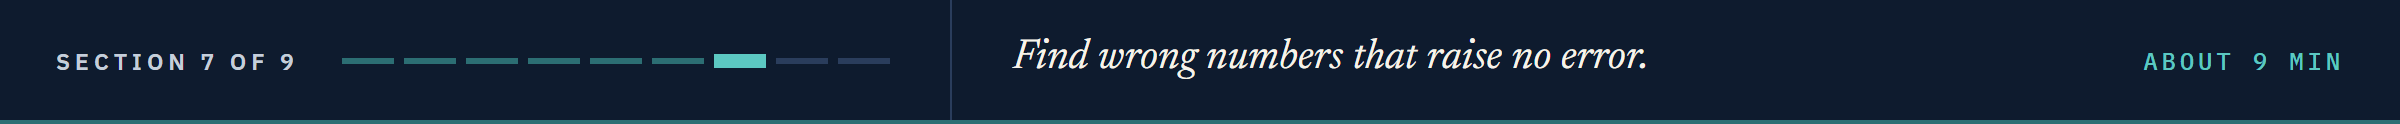

## 3.7 Wrong Numbers, No Error

### Income Without the Percent

Q. Work out QVNE's annual coupon income, 1,500,000 face at 5.25 percent: the analyst's way, then with the coupon divided by 100.

In [31]:
# the analyst's line, then the same line with the coupon divided by 100
face = 1500000
coupon = 5.25
print(f'As the analyst wrote it: {face * coupon:,.2f}')
print(f'Coupon divided by 100:   {face * coupon / 100:,.2f}')

As the analyst wrote it: 7,875,000.00
Coupon divided by 100:   78,750.00


The note's 7,875,000, with no error, a hundred times too big.
5.25 percent of 1,500,000 is near 79,000: the coupon was never divided by 100.

**Know roughly the answer before you run the code.**

### An Average Below the Lowest Coupon

Q. Work out the simple average coupon of the four bonds.

Q. An average must land between the lowest coupon, 4.75, and the highest, 7.5. If it does not, print the working on every pass.

Q. Add each coupon to the total.

In [32]:
# the analyst's loop for the average coupon
total = 0
for coupon in coupon_list:
    total = coupon
average_coupon = total / len(coupon_list)
print('The average coupon is', average_coupon)

The average coupon is 1.875


In [33]:
# the same loop, printing its working on every pass
total = 0
for coupon in coupon_list:
    total = coupon
    print('coupon:', coupon, ' total so far:', total)

coupon: 5.25  total so far: 5.25
coupon: 6.125  total so far: 6.125
coupon: 4.75  total so far: 4.75
coupon: 7.5  total so far: 7.5


In [34]:
# += adds each coupon to the running total, as in Part 1
total = 0
for coupon in coupon_list:
    total += coupon
average_coupon = total / len(coupon_list)
print('The average coupon is', average_coupon)

The average coupon is 5.90625


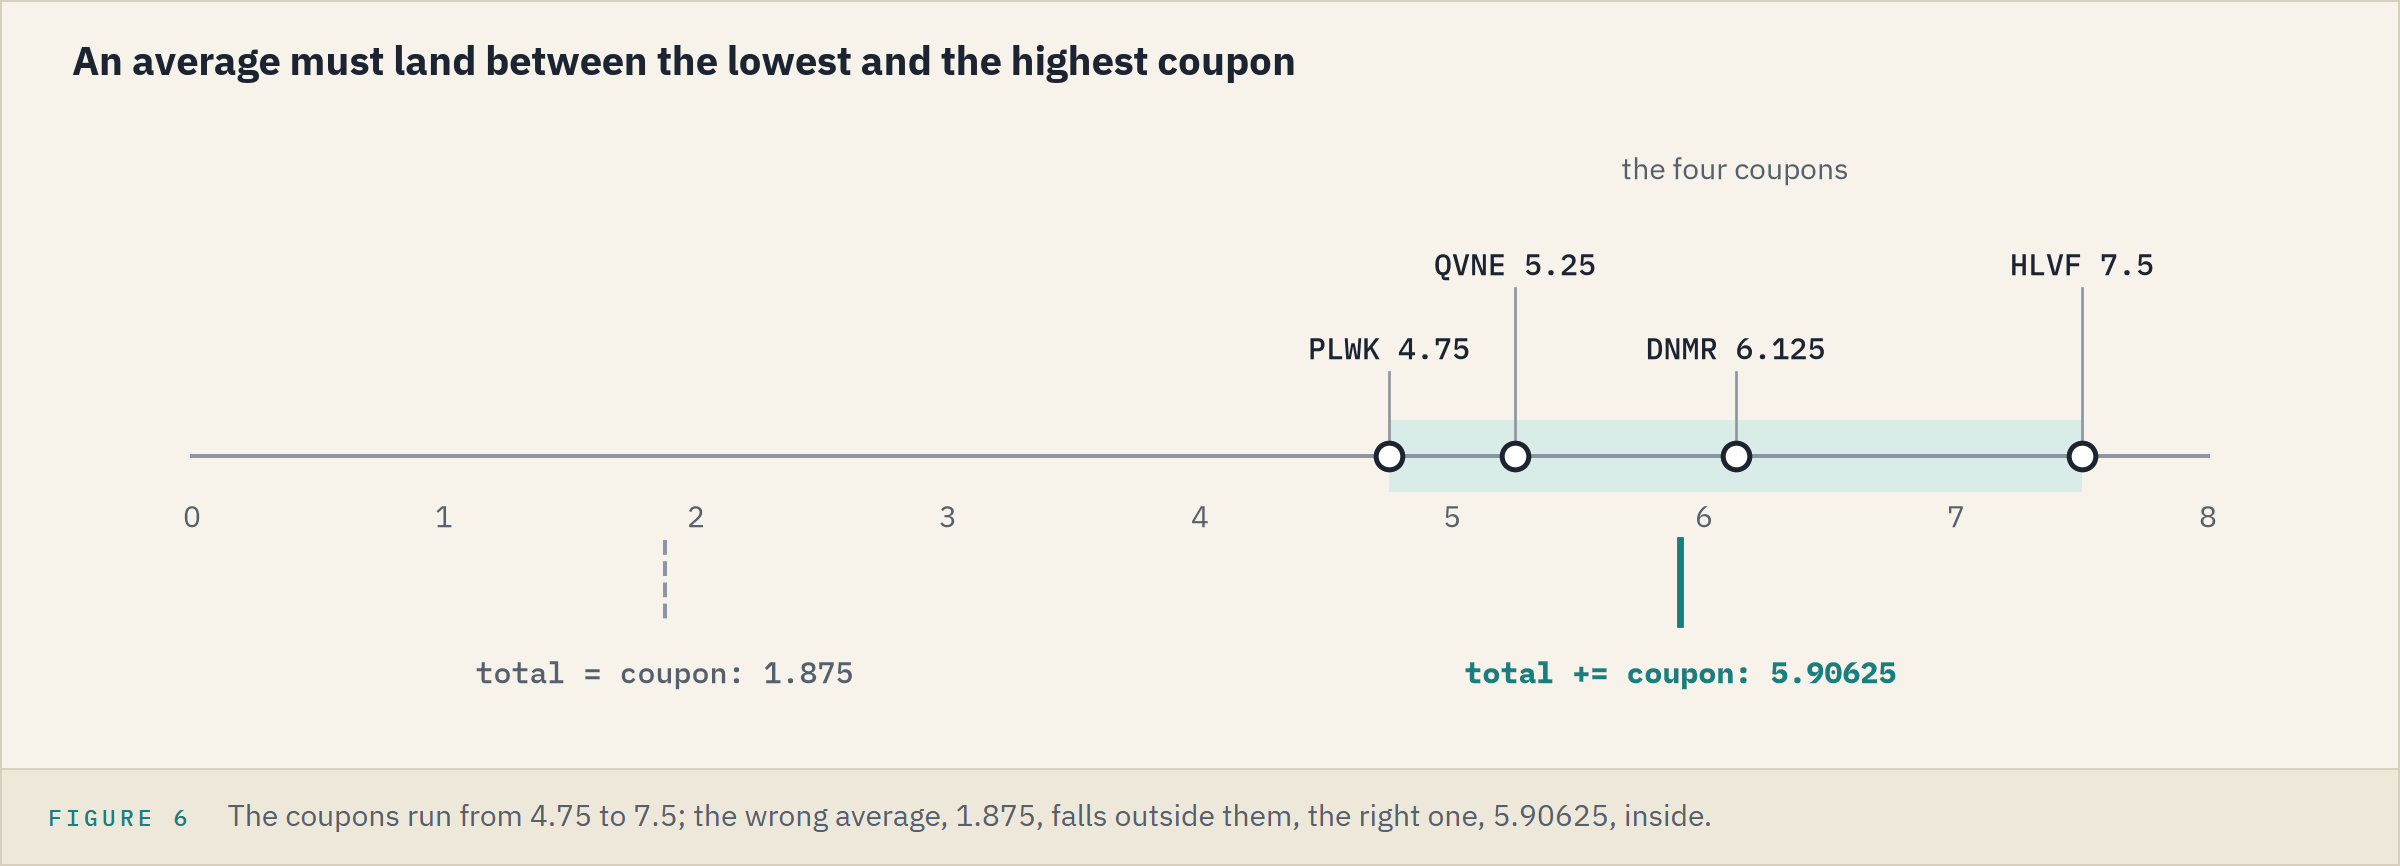

Each pass replaced the total, so it ended at 7.5, and 7.5 over 4 is 1.875.
Once the bug is found, the extra `print()` comes out.

**Excel side by side.** Evaluate Formula, on the Formulas tab, shows the working one step at a time, as a `print()` inside a loop does.

### Two Names, One List

Q. Mark QVNE at 99.0 in a what-if list, leaving the desk's prices alone.

Q. Put the desk's price back, and copy the list with `.copy()`.

In [35]:
# what looks like a second list, for a what-if mark on QVNE
what_if_list = price_list
what_if_list[0] = 99.0
print(f'What-if prices: {what_if_list}')
print(f'Desk prices:    {price_list}')

What-if prices: [99.0, 103.25, 95.0, 101.0]
Desk prices:    [99.0, 103.25, 95.0, 101.0]


In [36]:
# put the desk's price back; .copy() hands back a separate list with the same items
price_list[0] = 98.5
what_if_list = price_list.copy()
what_if_list[0] = 99.0
print(f'What-if prices: {what_if_list}')
print(f'Desk prices:    {price_list}')

What-if prices: [99.0, 103.25, 95.0, 101.0]
Desk prices:    [98.5, 103.25, 95.0, 101.0]


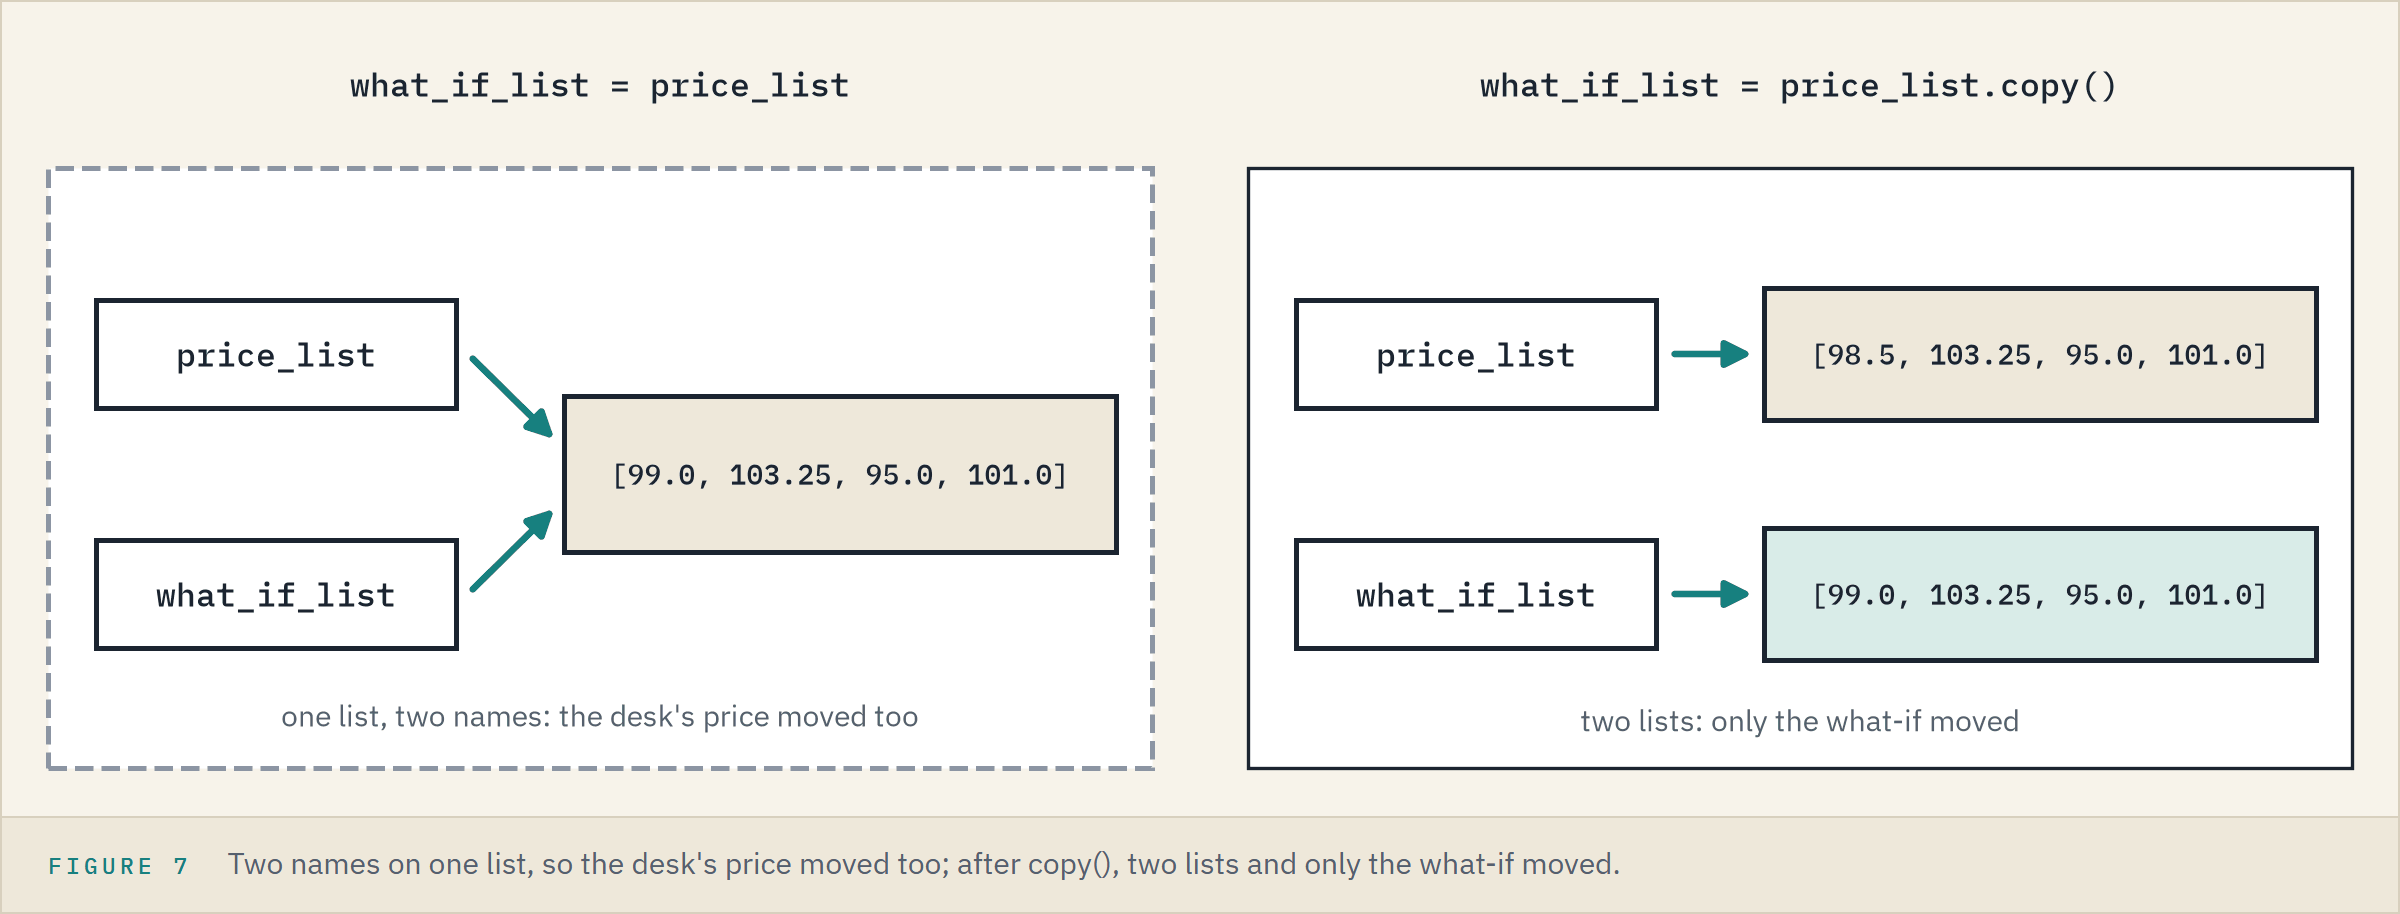

`what_if_list = price_list` made a second name, not a second list, so the 99.0 landed under both (mutable, Part 1).

**Excel side by side.** A pasted range is a separate copy from the moment it lands; in Python, ask for one with `.copy()`.

### A Built-in Name Taken

Q. The analyst keeps a running total under the name `sum`, then asks Python's `sum()` for the average.

Q. Remove our `sum` with `del`, and try again.

In [37]:
# a running total kept under the name sum: this cell is meant to fail
sum = 0
for coupon in coupon_list:
    sum += coupon
print(f'Total of the coupons: {sum}')
average_coupon = sum(coupon_list) / len(coupon_list)

Total of the coupons: 23.625


TypeError: 'float' object is not callable

In [38]:
# del removes our name, so sum is Python's own tool again
del sum
average_coupon = sum(coupon_list) / len(coupon_list)
print(f'The average coupon is {average_coupon}')

The average coupon is 5.90625


`'float' object is not callable`: to call a function is to run it with round brackets (Part 2), and a number cannot run.
Keep `sum`, `max`, `min`, `len`, `list`, `round`, and `type` for Python.

### Why 0.1 Plus 0.2 Is Not 0.3

Q. Fees of 0.1 and 0.2 of a point should add up to 0.3. Do they?

Q. What does Python hold for 0.1? Is a half plus a quarter exact?

Q. Round to show a number; compare two with `math.isclose()`.

In [39]:
# two fees, a tenth and two tenths of a point
total_fee = 0.1 + 0.2
print(total_fee)
print(total_fee == 0.3)

0.30000000000000004
False


In [40]:
# .20f: Part 1's .2f with 20 decimals; then a half plus a quarter
print(f'{0.1:.20f}')
print(0.5 + 0.25 == 0.75)
# round() for showing; isclose() asks: equal to within a tiny margin?
print(round(total_fee, 2))
print(math.isclose(total_fee, 0.3))

0.10000000000000000555
True
0.3
True


Python stores numbers in **binary**: Day 0's 4s, 2s, and 1s, carried on past the point as halves, quarters, and eighths:

<table align="left">
<tr><th align="left">Number</th><th align="left">In halves, quarters, eighths</th><th align="left">Stored exactly?</th></tr>
<tr><td align="left">0.75</td><td align="left">1/2 + 1/4</td><td align="left">yes</td></tr>
<tr><td align="left">99.125</td><td align="left">99 + 1/8</td><td align="left">yes</td></tr>
<tr><td align="left">0.1</td><td align="left">no mix adds up to it</td><td align="left">no: it keeps the nearest, which begins 0.10000000000000000555</td></tr>
</table>
<br clear="left">

**Excel side by side.** Excel stores numbers the same way, yet `=0.1+0.2=0.3` returns TRUE in Excel.
A total that ties in a sheet can fail an exact test in code, so code compares with `isclose()`.

**Some errors are not bugs at all: they arrive with the data.**

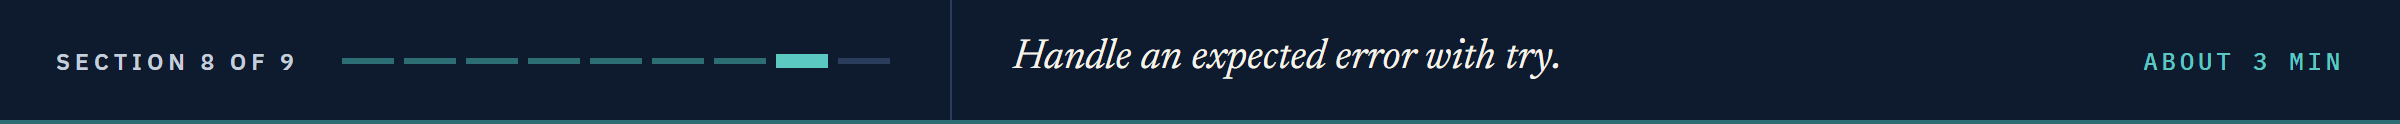

## 3.8 Expect the Error

### A Price Marked `n/a`

When one can be foreseen, tell Python what to do, so one bad value does not stop the run.
`try` and `except` handle it:

```
try:
    code that might fail
except TheErrorType:
    what to do if it fails
```

Q. Today's prices arrive as text, one marked 'n/a'. Convert each to a number.

Q. Convert under `try`, and report a bad price under `except ValueError`.

In [41]:
# today's prices arrive as text, one marked n/a: this cell is meant to fail
feed_text_list = ['98.5', '103.25', 'n/a', '101.0']
for ticker, text in zip(ticker_list, feed_text_list):
    price = float(text)
    print(ticker, 'is priced at', price)

QVNE is priced at 98.5
DNMR is priced at 103.25


ValueError: could not convert string to float: 'n/a'

In [42]:
# the same loop, with float() under try
for ticker, text in zip(ticker_list, feed_text_list):
    try:
        price = float(text)
        print(ticker, 'is priced at', price)
    except ValueError:
        print(ticker, 'has a price that is not a number:', text)

QVNE is priced at 98.5
DNMR is priced at 103.25
PLWK has a price that is not a number: n/a
HLVF is priced at 101.0


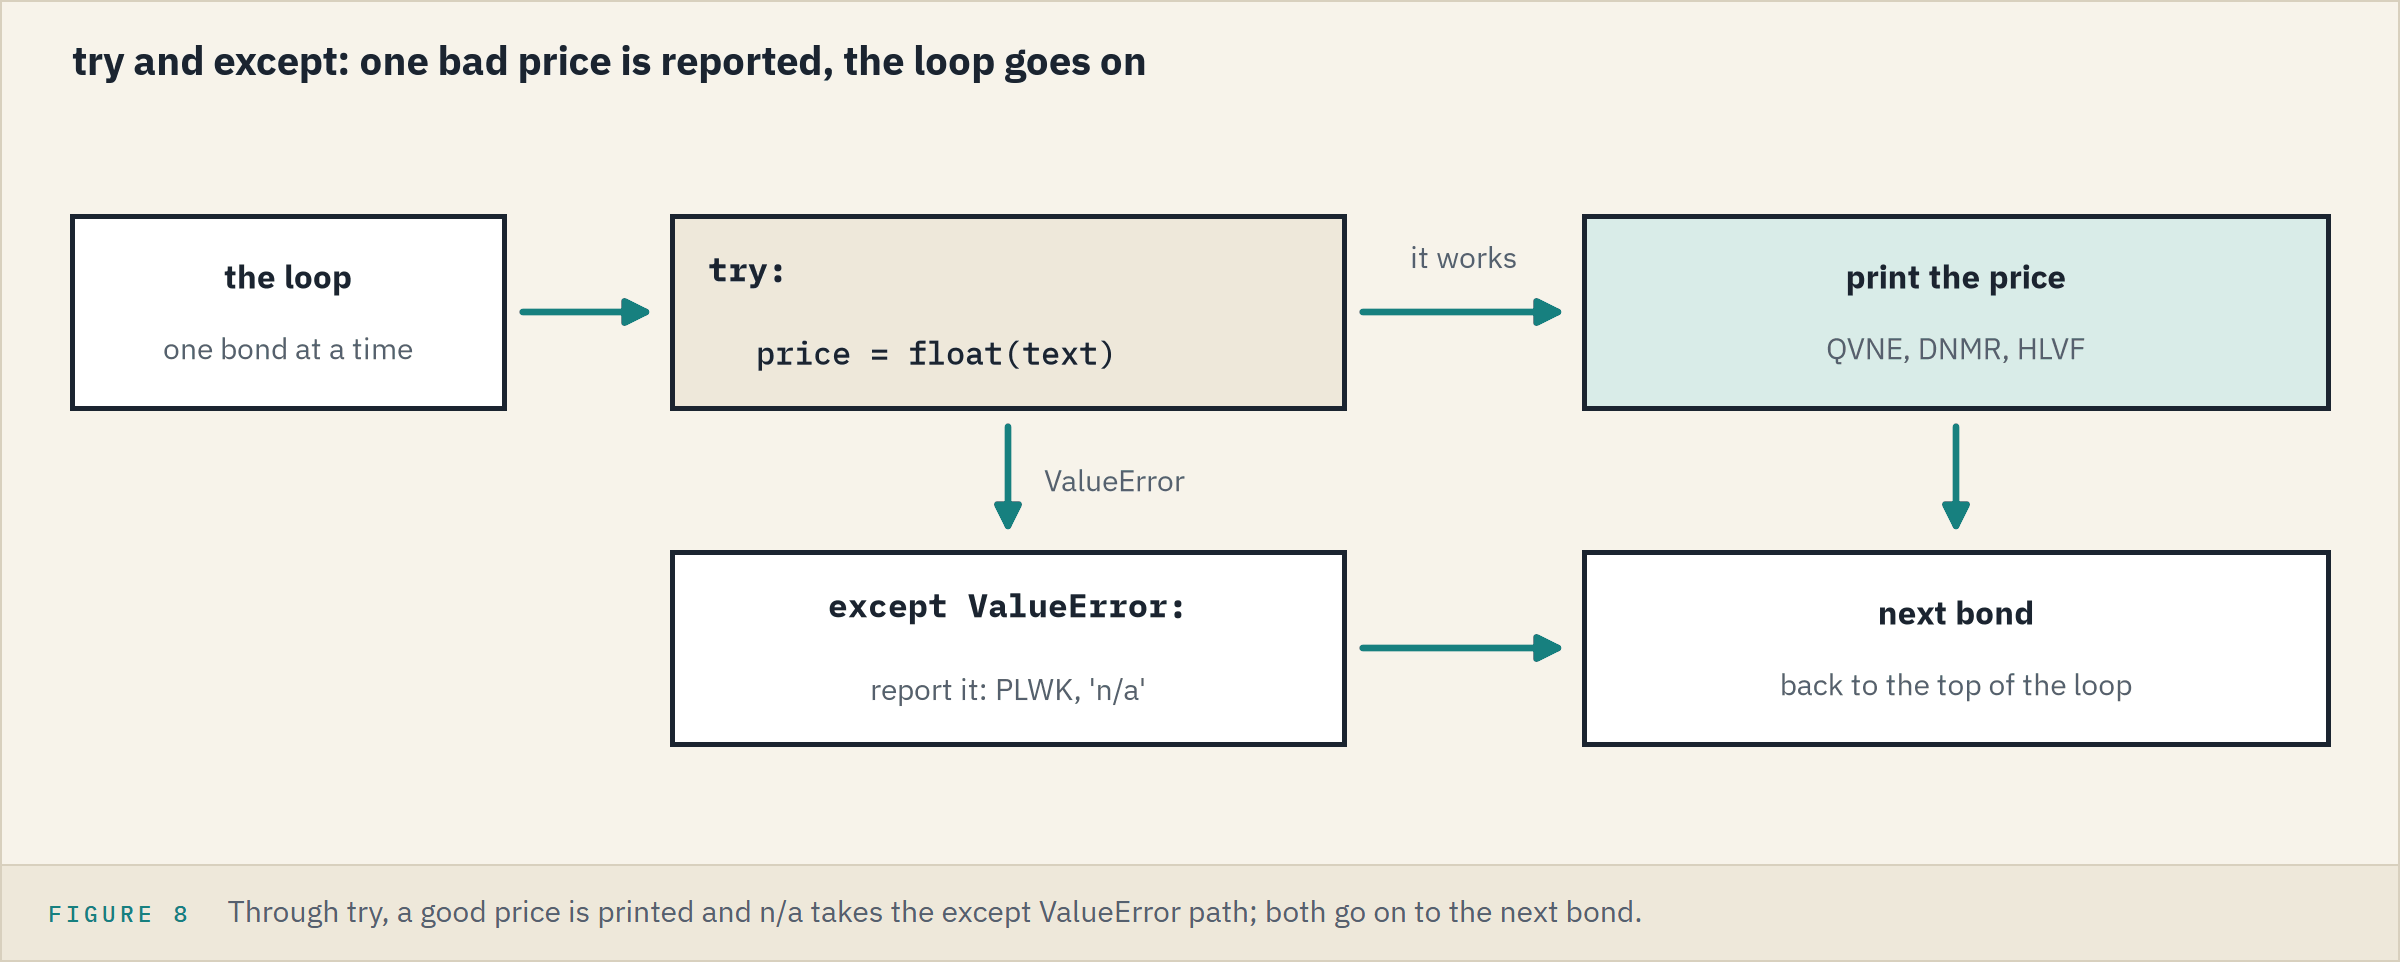

**Exception** is Python's word for an error, hence `except`; a bare `except:`, naming none, catches every error there is.

**Always name the error you expect.**

### A Bare `except` Hides a Typo

Q. The analyst drops the name from `except` and misspells `float`. What happens?

In [43]:
# float misspelled, and a bare except: shown to see the harm, never to copy
for ticker, text in zip(ticker_list, feed_text_list):
    try:
        price = flaot(text)
        print(ticker, 'is priced at', price)
    except:
        print(ticker, 'has a price that is not a number:', text)

QVNE has a price that is not a number: 98.5
DNMR has a price that is not a number: 103.25
PLWK has a price that is not a number: n/a
HLVF has a price that is not a number: 101.0


No red block, and all four bonds reported bad: the typo's `NameError` was caught and hidden.
Under `except ValueError:` the run would have stopped and named `flaot`.

**Excel side by side.** `=IFERROR(VALUE(A1),"bad price")` catches every kind of error, like a bare `except:`.
`IFNA` catches only `#N/A`, closer to naming the error: `=IFNA(XLOOKUP("Rating",A1:A3,B1:B3),"not found")`.

**Handling an error is not the same as noticing one.**

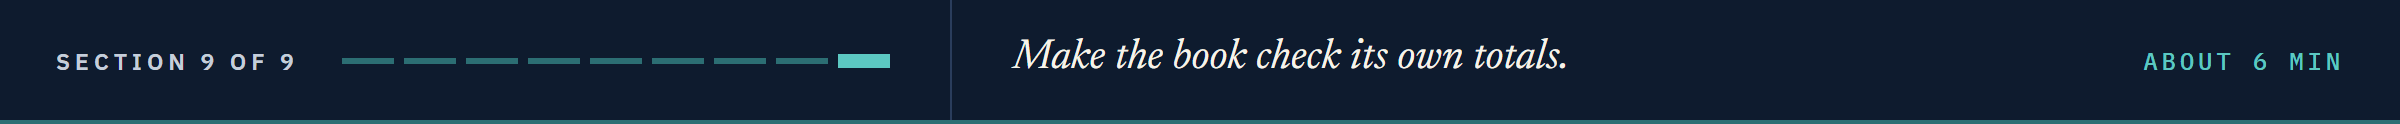

## 3.9 Checks That Stop

### State What Must Be True

A printed check needs a reader; an `assert` does not.
It states what must be true: silent when it is, and when not, it stops the run with your message.

```
assert condition, 'message to show if the condition is False'
```

Q. The position report says the faces add up to 3,000,000. State that as a check.

Q. Now the 250,000 position is keyed in twice. Run the same check.

In [44]:
# stop the run, with a message, unless the faces add up to the position report
total_face = sum(face_list)
assert total_face == 3000000, 'the faces do not add up to the position report'
print(f'Total face: {total_face:,}')

Total face: 3,000,000


In [45]:
# + joins two lists into one: here the 250,000 is keyed twice
# this cell is meant to fail
faces_with_repeat = face_list + [250000]
total_face = sum(faces_with_repeat)
assert total_face == 3000000, f'expected 3,000,000 face and found {total_face:,}'

AssertionError: expected 3,000,000 face and found 3,250,000

The second stops on the line that found the problem, with our message: nobody had to notice a number.
`assert` is for your own work: totals that tie, counts that match.

### A Function Refuses, the Caller Decides

`raise` stops the run with an error of the type you name.
Unlike `assert`, it always runs: Python started with `-O` skips every `assert`.

Q. Make `current_yield` refuse a price of zero or less, and say why.

Q. Call it with a good price, then with 0.

Q. Today's feed has a 0 for DNMR. Print the yields that can be worked out, and report the other.

In [46]:
def current_yield(coupon, price):
    """Take coupon (percent) and price (per 100 face); return current yield in percent."""
    # refuse a price that cannot be right, and say why
    if price <= 0:
        raise ValueError(f'the price must be above zero, and it is {price}')
    return coupon / price * 100

In [47]:
# a good price, then a price of zero: this cell is meant to fail
print(f'QVNE: {current_yield(5.25, 98.5):.2f} percent')
current_yield(5.25, 0)

QVNE: 5.33 percent


ValueError: the price must be above zero, and it is 0

In [48]:
# today's feed, with a zero for DNMR
feed_price_list = [98.5, 0, 95.0, 101.0]
for ticker, coupon, price in zip(ticker_list, coupon_list, feed_price_list):
    try:
        print(f'{ticker}: {current_yield(coupon, price):.2f} percent')
    except ValueError as problem:
        print(f'{ticker}: skipped, {problem}')

QVNE: 5.33 percent
DNMR: skipped, the price must be above zero, and it is 0
PLWK: 5.00 percent
HLVF: 7.43 percent


Two arrows again, as in 3.6.
Without the check, a zero raises a `ZeroDivisionError`, naming the arithmetic, not the cause; a negative price raises nothing and returns a negative yield.
`as problem` names the error, as Day 2's `with ... as` named the file.

### The Book Checks Itself

Q. Total the book's face, cost, and income.

Q. Tie each to the desk's figure: 3,000,000 face, 2,958,750 dollars of cost, 163,750 dollars of income.

In [49]:
# the book's three totals, from its own lists
book_face = sum(face_list)
book_cost = sum([face * price / 100 for face, price in zip(face_list, price_list)])
book_income = sum([face * coupon / 100 for face, coupon in zip(face_list, coupon_list)])

In [50]:
# each total must tie to the desk's figure, or the run stops on that line
assert book_face == 3000000, 'face does not tie'
assert math.isclose(book_cost, 2958750), 'cost does not tie'
assert math.isclose(book_income, 163750), 'income does not tie'
print(f'Book ties: {book_face:,} face, ${book_cost:,.2f} cost, ${book_income:,.2f} income')

Book ties: 3,000,000 face, $2,958,750.00 cost, $163,750.00 income


Cost and income carry decimals, so they compare with `isclose()`.

**Excel side by side.** The three tools, and Excel's nearest:

<table align="left">
<tr><th align="left">Python</th><th align="left">Who uses it</th><th align="left">Excel's nearest</th></tr>
<tr><td align="left"><code>assert</code></td><td align="left">you, on your own totals</td><td align="left">a check cell, <code>=IF(SUM(F2:F5)=3000000,"OK","CHECK")</code>, which calculates on</td></tr>
<tr><td align="left"><code>raise</code></td><td align="left">a function, on a bad value it is handed</td><td align="left">Data Validation (Data tab), which refuses a value as it is typed</td></tr>
<tr><td align="left"><code>try</code> and <code>except</code></td><td align="left">the caller, deciding what to do</td><td align="left"><code>IFNA</code>, as in 3.8</td></tr>
</table>
<br clear="left">

**The rule from here on: a check that matters is an `assert` or a `raise`, never a printed number.**

## You Can Now

By the end of this notebook, you can:

* Read a traceback: the error type, the message, and the line.
* Name the common errors and say what each one is telling you.
* Follow an error inside a function back to the line that caused it.
* Catch a wrong number that raises no error.
* Stop a run with `assert`, and handle bad data with `try` and `except`.

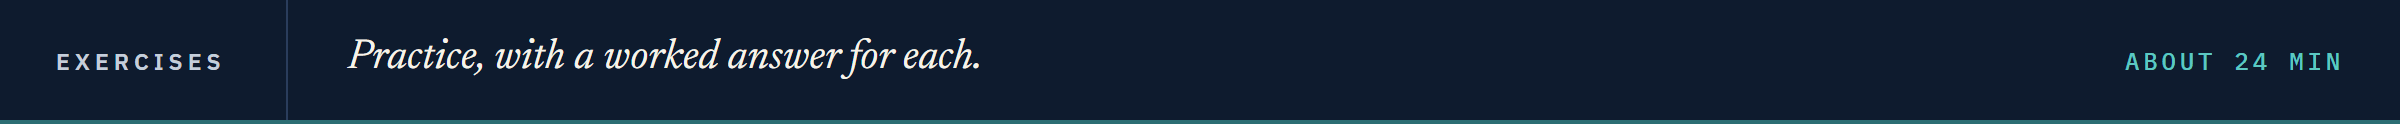

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The analyst also wrote code for a second desk.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Score</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">4.375</td><td align="left">96.25</td><td align="left">A</td><td align="left">6</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">5.00</td><td align="left">100.00</td><td align="left">BBB-</td><td align="left">10</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">8.25</td><td align="left">104.50</td><td align="left">B</td><td align="left">15</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

Exercises 1 to 5, 7, and 8 each hold one bug: run the code, read what happens, and fix it **in the same cell**.
Exercise 6 asks for a function.
Run the next cell first, then the check cell under each exercise.

In [51]:
def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
    elif answer == expected:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# the second desk's data
ticker_list = ['TRNW', 'OSMC', 'CLDB']
coupon_list = [4.375, 5.0, 8.25]
price_list = [96.25, 100.0, 104.5]
face_list = [2000000, 1250000, 500000]

# each answer starts as the placeholder ..., which check() reads as not attempted
ex1_total_face = ...
ex2_current_yield = ...
ex3_tickers = ...
ex4_average_price = ...
ex5_total_coupon = ...
ex5_bad_count = ...
ex6_average = ...
ex6_stops = ...
ex7_what_if = ...
ex8_ig_count = ...

### Exercise 1

Q. Fix this code so that **ex1_total_face** holds the total face held.

In [52]:
ex1_total_face = 0
for face in face_list
    ex1_total_face = ex1_total_face + face

print('The total face held is', ex1_total_face)

SyntaxError: expected ':' (1485305921.py, line 2)

In [53]:
check('Exercise 1', ex1_total_face, 3750000)

Exercise 1: not attempted yet


### Exercise 2

Q. Fix this code so that **ex2_current_yield** holds TRNW's current yield, rounded to 2 decimals.

In [54]:
bond = {'Ticker': 'TRNW', 'Coupon': 4.375, 'Price': 96.25}

ex2_current_yield = round(bond['coupon'] / bond['price'] * 100, 2)
print('The current yield of TRNW is', ex2_current_yield)

KeyError: 'coupon'

In [55]:
check('Exercise 2', ex2_current_yield, 4.55)

Exercise 2: not attempted yet


### Exercise 3

Q. Fix this code so that **ex3_tickers** lists all three tickers, taken by position.

In [56]:
ex3_tickers = []
for i in range(1, 4):
    ex3_tickers.append(ticker_list[i])

print(ex3_tickers)

IndexError: list index out of range

In [57]:
check('Exercise 3', ex3_tickers, ['TRNW', 'OSMC', 'CLDB'])

Exercise 3: not yet. You have ['OSMC', 'CLDB']


### Exercise 4

Q. The prices arrived from a file as text. Fix this code so that **ex4_average_price** holds their simple average.

In [58]:
price_text_list = ['96.25', '100.0', '104.5']

total = 0
for text in price_text_list:
    total = total + text

ex4_average_price = total / len(price_text_list)
print('The average price is', ex4_average_price)

TypeError: unsupported operand type(s) for +: 'int' and 'str'

In [59]:
check('Exercise 4', ex4_average_price, 100.25)

Exercise 4: not attempted yet


### Exercise 5

Q. One coupon arrived as 'TBD'. Fix this code with `try` and `except`, so that **ex5_total_coupon** adds up the coupons that are numbers and **ex5_bad_count** counts the ones that are not.

In [60]:
coupon_text_list = ['4.375', 'TBD', '8.25']

ex5_total_coupon = 0
ex5_bad_count = 0
for text in coupon_text_list:
    ex5_total_coupon = ex5_total_coupon + float(text)

print(f'Total of the coupons that are numbers: {ex5_total_coupon}')
print(f'Values that are not numbers: {ex5_bad_count}')

ValueError: could not convert string to float: 'TBD'

In [61]:
check('Exercise 5 total', ex5_total_coupon, 12.625)
check('Exercise 5 bad values', ex5_bad_count, 1)

Exercise 5 total: not yet. You have 4.375
Exercise 5 bad values: not yet. You have 0


### Exercise 6

Q. Write **average_price**: it takes a list of prices and returns their simple average.
If the list is empty it must stop, with `raise ValueError` and the message 'the price list is empty'.

In [62]:
def average_price(prices):
    """Return the simple average of a list of prices. Stop if the list is empty."""
    ...

In [63]:
ex6_average = average_price(price_list)

# does the function stop when it is handed an empty list?
if ex6_average is not None:
    try:
        average_price([])
        ex6_stops = False
    except ValueError:
        ex6_stops = True

check('Exercise 6 average', ex6_average, 100.25)
check('Exercise 6 stops on an empty list', ex6_stops, True)

Exercise 6 average: not attempted yet
Exercise 6 stops on an empty list: not attempted yet


### Exercise 7

Q. This code should leave `price_list` as it is and build **ex7_what_if**, with CLDB marked at 99.5.
It runs with no error; fix it so that both checks pass.

In [64]:
price_list = [96.25, 100.0, 104.5]

ex7_what_if = price_list
ex7_what_if[2] = 99.5

print(f'What-if prices: {ex7_what_if}')
print(f'Desk prices:    {price_list}')

What-if prices: [96.25, 100.0, 99.5]
Desk prices:    [96.25, 100.0, 99.5]


In [65]:
check('Exercise 7 what-if list', ex7_what_if, [96.25, 100.0, 99.5])
check('Exercise 7 desk list', price_list, [96.25, 100.0, 104.5])

Exercise 7 what-if list: correct
Exercise 7 desk list: not yet. You have [96.25, 100.0, 99.5]


### Exercise 8: AI check

An AI assistant wrote code to count the investment grade bonds, those with a score of 10 or lower; it has one bug.

Q. Count them yourself from the table first. Then run the code. Does it agree?

Q. Find the bug and fix the code below, so that **ex8_ig_count** holds the right answer.

In [66]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
score_list = [6, 10, 15]

ex8_ig_count = 0
for score in score_list:
    if score < 10:
        ex8_ig_count = ex8_ig_count + 1

print('Investment grade bonds:', ex8_ig_count)

Investment grade bonds: 1


In [67]:
check('Exercise 8', ex8_ig_count, 2)

Exercise 8: not yet. You have 1


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Fix every cell</td><td align="left">18 red blocks read from the last line up: 16 bugs fixed, and 2 checks doing their job</td></tr>
<tr><td align="left">Find the wrong numbers</td><td align="left">QVNE's 7,875,000 is 78,750 dollars; the 1.875 average coupon is 5.90625</td></tr>
<tr><td align="left">Make the book check its own totals</td><td align="left">three <code>assert</code> lines tie the face, the cost, and the income</td></tr>
</table>
<br clear="left">

A red block no longer says you failed: it gives the type, the message, and the line.
Be proud: you now read it calmly and fix the line.
Today `current_yield` had to be handed each bond's coupon and price, and a bad price walked in from outside.
On Day 4 a class makes a Bond that carries its own data and its own calculations.

[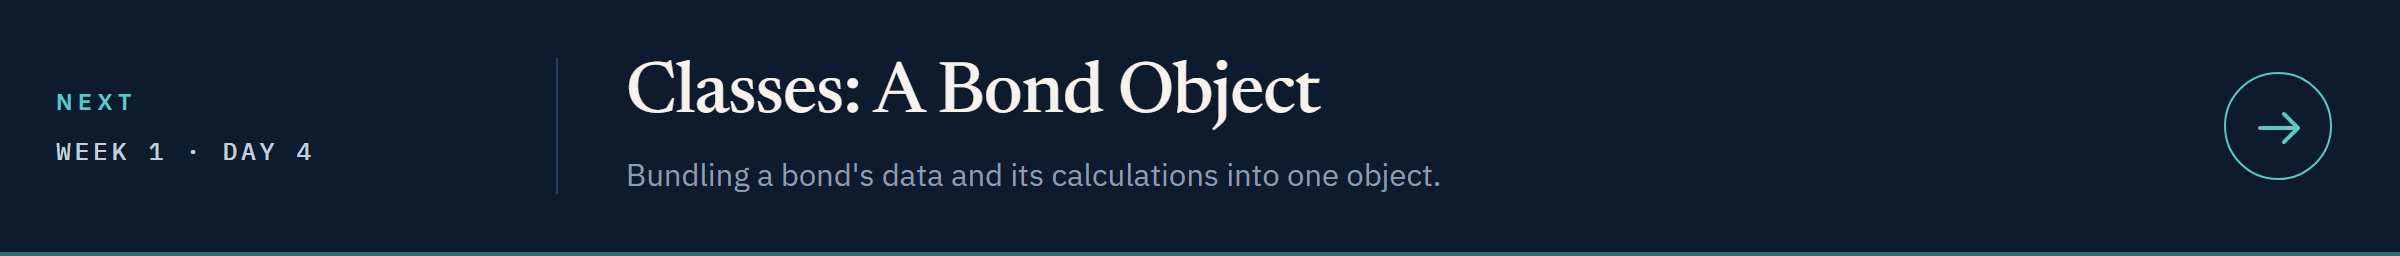](../day4/04_classes_a_bond_object.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day4/04_classes_a_bond_object.ipynb)